# ICU Mortality Prediction on MIMIC-IV — Part 2: Modelling, Evaluation and Final Pipeline

**Team:** Mudassar, Touseef, Ifraz
**Project:** *Calibration, Missing Data, Validation Design and Subgroup Reporting in Machine-Learning Models for ICU Mortality Prediction on MIMIC Data*
**Part 1 (data preparation + EDA):** `1_eda/MIMIC_ICU_Mortality_EDA_GPU_executed.ipynb`

**Task.** Predict **in-hospital mortality** from the first 24 hours of an adult patient's first ICU stay
(cohort of 51,838 stays, 10.65% mortality). Part 1 built the cohort, extracted and cleaned the features, split the data
by patient into train (80%) and test (20%) sets, and fitted all preprocessing on the training set only.
This notebook starts from those model-ready files.

### Link to our systematic review
Our project is a systematic review of how published MIMIC-based ICU mortality models handle **calibration (RQ1),
missing data (RQ2), validation design and leakage (RQ3), baselines (RQ5) and subgroup reporting (RQ6)**. Section 6 of
the review protocol defines an *illustrative case study* that applies the review's own recommendations to one fixed
MIMIC-IV cohort. This notebook is that case study, extended with the model comparison required for the course:

| Protocol requirement (case study) | Where in this notebook |
|---|---|
| L2 logistic regression and XGBoost as the core comparison (H3: equal tuning, same cohort) | Sections 3–4, 7.4 |
| A published severity-score baseline (SOFA) | Sections 3.2, 7 |
| Patient-grouped split, train-only preprocessing | Section 2 (and Part 1) |
| Calibration protocol fixed in advance: 10 equal-frequency bins, slope and intercept, **isotonic recalibration fitted on validation only** | Sections 1.4, 5.4 |
| Paired bootstrap CIs on AUPRC and ECE | Section 7.4 |
| Missingness handling: complete-case vs median imputation vs imputation + indicator (+ native tree handling) — RQ2 | Section 11.1 |
| Temporal hold-out with the coarse `anchor_year_group` — RQ3 | Section 11.2 |
| Subgroups by age band, sex, admission type, race, insurance — RQ6 | Section 10 |

| Section | Content | Course requirement covered |
|---|---|---|
| 1 | Environment, configuration, reproducibility | — |
| 2 | Data loading and **train / validation / test** split | data splitting |
| 3 | **Model selection** and rationale, SOFA baseline | model selection & implementation |
| 4 | Baseline training and **hyperparameter tuning** (Optuna, grouped 3-fold CV) | training & tuning |
| 5 | **Optimisation**: tuning gain, class weighting, feature set, probability calibration, ensemble, decision threshold | optimisation & performance improvement |
| 6 | **Final model selection** (on validation data only) | final model selection |
| 7 | **Test-set evaluation** with 95% bootstrap CIs, DeLong and paired-bootstrap tests | evaluation with appropriate metrics |
| 8 | **Model comparison** | comparison of approaches |
| 9 | **Visualisation and analysis**: ROC, PR, calibration, decision curves, confusion matrix, SHAP | results visualisation |
| 10 | **Subgroup (fairness) analysis** | performance analysis |
| 11 | **Protocol experiments**: missing-data strategies, temporal validation | approach comparison |
| 12 | **Complete ML pipeline**: save, reload, `predict_risk()` | complete ML pipeline |
| 13 | Conclusions and limitations | — |

**Golden rule of this notebook:** every *choice* — hyperparameters, calibration, ensemble, decision threshold and the
final model — is made on training/validation data only. The test set is first opened in Section 7, after the final
model is fixed; Sections 10–11 are pre-specified analyses that only *report* on it.

## 1. Environment setup

### 1.1 Libraries
The notebook needs `pandas`, `numpy`, `pyarrow`, `scikit-learn`, `xgboost`, `lightgbm`, `optuna`, `matplotlib`,
`seaborn`, `scipy` and `joblib`. All are pre-installed on Kaggle. The cell below installs any that are missing
(only possible when internet access is on). `optuna` is optional: without it the notebook falls back to random search.

In [1]:
import importlib, subprocess, sys

REQUIRED = {"pandas": "pandas", "numpy": "numpy", "pyarrow": "pyarrow", "sklearn": "scikit-learn",
            "xgboost": "xgboost", "lightgbm": "lightgbm", "matplotlib": "matplotlib", "seaborn": "seaborn",
            "scipy": "scipy", "joblib": "joblib", "optuna": "optuna"}
for module, package in REQUIRED.items():
    try:
        importlib.import_module(module)
    except ImportError:
        print(f"Installing {package} ...")
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])
        except Exception as exc:  # no internet on the Kaggle kernel
            print(f"  could not install {package}: {exc}")

C:\Users\<user>\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import os, json, time, glob, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import joblib

import sklearn
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, roc_curve,
                             precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
import xgboost as xgb
import lightgbm as lgb

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    HAS_OPTUNA = True
except ImportError:
    HAS_OPTUNA = False

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
pd.set_option("display.width", 160)

for lib in [np, pd, sklearn, xgb, lgb]:
    print(f"{lib.__name__:<10} {lib.__version__}")
print("optuna    ", optuna.__version__ if HAS_OPTUNA else "not available -> random search")

numpy      2.4.5
pandas     3.0.3
sklearn    1.8.0
xgboost    3.4.1
lightgbm   4.7.0
optuna     5.1.0


### 1.2 Paths and hardware
The notebook detects whether it runs on **Kaggle** (processed files attached as a private dataset under
`/kaggle/input/`) or **locally** (`E:\patients data`). It searches for `train_processed.parquet`, so the name of the
attached dataset does not matter. A GPU, when present, is used by XGBoost.

In [3]:
IN_KAGGLE = Path("/kaggle/input").exists()

if IN_KAGGLE:
    hits = sorted(glob.glob("/kaggle/input/**/train_processed.parquet", recursive=True))
    assert hits, "Attach the dataset that contains train_processed.parquet (Part 1 output)."
    PROC_DIR = Path(hits[0]).parent
    OUT_DIR = Path("/kaggle/working")
else:
    PROJECT_DIR = Path(r"E:\patients data")
    PROC_DIR = PROJECT_DIR / "data" / "processed"
    OUT_DIR = PROJECT_DIR / "2_model"

FIG_DIR, RES_DIR, MODEL_DIR = OUT_DIR / "figures", OUT_DIR / "results", OUT_DIR / "saved_models"
for d in (FIG_DIR, RES_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)


def find_file(name):
    # look next to the train file first, then anywhere in the attached input
    p = PROC_DIR / name
    if p.exists():
        return p
    if IN_KAGGLE:
        hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
        if hits:
            return Path(hits[0])
    return None


def has_gpu():
    try:
        return subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
    except (FileNotFoundError, OSError):
        return False


GPU = has_gpu()
print("Running on   :", "Kaggle" if IN_KAGGLE else "local machine")
print("Input folder :", PROC_DIR)
print("Output folder:", OUT_DIR)
print("GPU          :", GPU)
if GPU:
    print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                         capture_output=True, text=True).stdout.strip())

Running on   : local machine
Input folder : E:\patients data\data\processed
Output folder: E:\patients data\2_model
GPU          : False


### 1.3 Configuration and reproducibility
All randomness is controlled by one seed (42, the same as Part 1). `FAST` mode (environment variable `ICU_FAST=1`) is
only for a quick smoke test: it subsamples the data and runs 2 tuning trials per model. **The submitted run uses the
full data.** To fit a 1-hour compute budget, tuning uses 3 grouped folds and 6–25 Optuna trials per model, and CIs
use 500 bootstrap resamples; TPE search usually reaches most of its gain within the first 20 trials.

In [4]:
SEED = 42
np.random.seed(SEED)

FAST = os.environ.get("ICU_FAST", "0") == "1"
N_FOLDS = 3                                   # grouped CV folds used for tuning (3 to fit the time budget)
N_TRIALS = {"LogReg": 15, "RandomForest": 8, "XGBoost": 25, "LightGBM": 20, "MLP": 6}
N_BOOT = 500                                  # bootstrap resamples for 95% CIs on the test set
N_BOOT_SUB = 200                              # bootstrap resamples per subgroup
if FAST:
    N_FOLDS, N_BOOT, N_BOOT_SUB = 3, 50, 30
    N_TRIALS = {k: 2 for k in N_TRIALS}

MODEL_NAMES = ["LogReg", "RandomForest", "XGBoost", "LightGBM", "MLP"]
CAL_METHOD = "isotonic"        # pre-specified in the review protocol (Section 6): isotonic, fitted on validation only
N_CAL_BINS = 10                # pre-specified: 10 equal-frequency bins for ECE and reliability curves
# fixed categorical palette - colour follows the model, never its rank
PALETTE = {"LogReg": "#2a78d6", "RandomForest": "#eb6834", "XGBoost": "#1baf7a",
           "LightGBM": "#eda100", "MLP": "#e87ba4", "SOFA": "#008300", "Ensemble": "#6250d6"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False,
                     "axes.spines.right": False, "grid.color": "#e6e6e3", "lines.linewidth": 2})


def errbar(lower, upper):
    # asymmetric error-bar lengths, clipped at 0 (a point estimate can sit outside its percentile CI)
    return [np.clip(np.asarray(lower, float), 0, None), np.clip(np.asarray(upper, float), 0, None)]


def savefig(name):
    # save the current figure to figures/<name>.png (also reused in the IEEE report)
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()


print("FAST mode:", FAST, "| folds:", N_FOLDS, "| trials:", N_TRIALS, "| bootstrap:", N_BOOT)

FAST mode: False | folds: 3 | trials: {'LogReg': 15, 'RandomForest': 8, 'XGBoost': 25, 'LightGBM': 20, 'MLP': 6} | bootstrap: 500


### 1.4 Evaluation helpers
Clinical risk models must be judged on **discrimination** *and* **calibration**, not on accuracy (with 10.7% deaths a
model that predicts "survives" for everyone is 89% accurate). The helper functions below implement:

| Metric | Meaning | Ideal |
|---|---|---|
| AUROC | probability that a random death is ranked above a random survivor | 1 (0.5 = chance) |
| AUPRC (average precision) | precision–recall trade-off; sensitive to the rare class | 1 (baseline = prevalence ≈ 0.107) |
| Brier score | mean squared error of the predicted probability | 0 |
| ECE | expected calibration error: weighted mean \|observed − predicted\| over 10 risk bins | 0 |
| Calibration slope | slope of the logistic regression of the outcome on logit(p); < 1 = over-confident | 1 |
| Calibration intercept | calibration-in-the-large (slope fixed at 1); > 0 = risk under-estimated | 0 |
| Sensitivity, specificity, PPV, NPV, F1 | at a decision threshold chosen on validation data | — |

plus **percentile-bootstrap 95% CIs**, the paired **DeLong test** for comparing AUROCs, a **paired bootstrap** for
differences in AUPRC/ECE between two models, **decision-curve analysis** (net benefit) and **subgroup tables**.
ECE uses **10 equal-frequency (quantile) bins**, as fixed in the protocol, so every bin holds the same number of stays.

In [5]:
# Clinical risk-model evaluation helpers.
"""Clinical risk-model evaluation helpers (discrimination, calibration, CIs, DeLong, DCA, subgroups).

Usage:  from clinical_metrics import evaluate, bootstrap_ci, delong_test, ...
All functions take y (0/1 array) and p (predicted probability of the positive class).
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             roc_auc_score, roc_curve)

EPS = 1e-12


def _logit(p):
    p = np.clip(np.asarray(p, float), EPS, 1 - EPS)
    return np.log(p / (1 - p))


def expected_calibration_error(y, p, n_bins=10, strategy="quantile"):
    """ECE: weighted mean |observed - predicted| over bins."""
    y, p = np.asarray(y), np.asarray(p)
    if strategy == "quantile":
        edges = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))
    else:
        edges = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, len(edges) - 2)
    ece = 0.0
    for b in range(len(edges) - 1):
        m = idx == b
        if m.any():
            ece += m.mean() * abs(y[m].mean() - p[m].mean())
    return ece


def calibration_slope_intercept(y, p):
    """Slope: logistic regression of y on logit(p). Intercept: calibration-in-the-large (slope fixed at 1)."""
    lp = _logit(p).reshape(-1, 1)
    slope = LogisticRegression(C=1e10, max_iter=1000).fit(lp, y).coef_[0, 0]
    # intercept with offset: solve for a in logit(P(y=1)) = a + lp via Newton steps
    a, off = 0.0, lp.ravel()
    for _ in range(50):
        mu = 1 / (1 + np.exp(-(a + off)))
        step = (np.sum(y - mu)) / max(np.sum(mu * (1 - mu)), EPS)
        a += step
        if abs(step) < 1e-10:
            break
    return slope, a


def evaluate(y, p, threshold=0.5):
    y, p = np.asarray(y).astype(int), np.asarray(p, float)
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if tp + fn else np.nan
    spec = tn / (tn + fp) if tn + fp else np.nan
    ppv = tp / (tp + fp) if tp + fp else np.nan
    npv = tn / (tn + fn) if tn + fn else np.nan
    slope, intercept = calibration_slope_intercept(y, p)
    return {
        "AUROC": roc_auc_score(y, p),
        "AUPRC": average_precision_score(y, p),
        "Brier": brier_score_loss(y, p),
        "ECE": expected_calibration_error(y, p),
        "Cal_slope": slope,
        "Cal_intercept": intercept,
        "Sensitivity": sens,
        "Specificity": spec,
        "PPV": ppv,
        "NPV": npv,
        "F1": 2 * ppv * sens / (ppv + sens) if ppv and sens else np.nan,
    }


def bootstrap_ci(y, p, threshold=0.5, n_boot=1000, seed=42, alpha=0.05):
    y, p = np.asarray(y).astype(int), np.asarray(p, float)
    rng = np.random.default_rng(seed)
    point = evaluate(y, p, threshold)
    boots = []
    n = len(y)
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        if y[i].min() == y[i].max():
            continue
        boots.append(evaluate(y[i], p[i], threshold))
    b = pd.DataFrame(boots)
    out = pd.DataFrame({
        "estimate": pd.Series(point),
        "ci_low": b.quantile(alpha / 2),
        "ci_high": b.quantile(1 - alpha / 2),
    })
    out["formatted"] = [f"{e:.3f} ({l:.3f}–{h:.3f})" for e, l, h in out[["estimate", "ci_low", "ci_high"]].values]
    return out


def _midrank(x):
    order = np.argsort(x)
    xs = x[order]
    n = len(x)
    ranks = np.empty(n)
    i = 0
    while i < n:
        j = i
        while j < n and xs[j] == xs[i]:
            j += 1
        ranks[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    out = np.empty(n)
    out[order] = ranks
    return out


def delong_test(y, p1, p2):
    """Paired DeLong test for two correlated AUROCs. Returns (auc1, auc2, diff, z, p_value)."""
    y = np.asarray(y).astype(int)
    preds = np.vstack([np.asarray(p1, float), np.asarray(p2, float)])
    pos, neg = preds[:, y == 1], preds[:, y == 0]
    m, n = pos.shape[1], neg.shape[1]
    aucs, v01, v10 = [], [], []
    for k in range(2):
        tx, ty = _midrank(pos[k]), _midrank(neg[k])
        tz = _midrank(np.concatenate([pos[k], neg[k]]))
        aucs.append(tz[:m].sum() / (m * n) - (m + 1) / (2 * n))
        v01.append((tz[:m] - tx) / n)
        v10.append(1 - (tz[m:] - ty) / m)
    s = np.cov(np.array(v01)) / m + np.cov(np.array(v10)) / n
    var = s[0, 0] + s[1, 1] - 2 * s[0, 1]
    diff = aucs[0] - aucs[1]
    z = diff / np.sqrt(var) if var > 0 else 0.0
    return {"AUROC_1": aucs[0], "AUROC_2": aucs[1], "diff": diff, "z": z,
            "p_value": 2 * stats.norm.sf(abs(z))}


def youden_threshold(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[np.argmax(tpr - fpr)])


def threshold_for_sensitivity(y, p, target=0.80):
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[np.argmax(tpr >= target)])


def decision_curve(y, p, thresholds=None):
    y, p = np.asarray(y).astype(int), np.asarray(p, float)
    thresholds = np.arange(0.01, 0.51, 0.01) if thresholds is None else np.asarray(thresholds)
    n, prev = len(y), y.mean()
    rows = []
    for t in thresholds:
        pred = p >= t
        tp = np.sum(pred & (y == 1))
        fp = np.sum(pred & (y == 0))
        w = t / (1 - t)
        rows.append({"threshold": t,
                     "net_benefit_model": tp / n - fp / n * w,
                     "net_benefit_all": prev - (1 - prev) * w,
                     "net_benefit_none": 0.0})
    return pd.DataFrame(rows)


def subgroup_table(y, p, groups, threshold=0.5, n_boot=500, seed=42, min_events=100):
    y, p, groups = np.asarray(y).astype(int), np.asarray(p, float), pd.Series(np.asarray(groups))
    rows = []
    for g in groups.dropna().unique():
        m = (groups == g).values
        if y[m].min() == y[m].max():
            continue
        ci = bootstrap_ci(y[m], p[m], threshold, n_boot=n_boot, seed=seed)
        row = {"group": g, "n": int(m.sum()), "deaths": int(y[m].sum()),
               "mortality": y[m].mean(), "mean_pred": p[m].mean(),
               "unstable": y[m].sum() < min_events}
        for metric in ["AUROC", "AUPRC", "Brier", "ECE", "Cal_slope", "Cal_intercept", "Sensitivity", "Specificity"]:
            row[metric] = ci.loc[metric, "estimate"]
            row[f"{metric}_lo"] = ci.loc[metric, "ci_low"]
            row[f"{metric}_hi"] = ci.loc[metric, "ci_high"]
        rows.append(row)
    return pd.DataFrame(rows).sort_values("n", ascending=False).reset_index(drop=True)


def plot_calibration(ax, y, p, label=None, n_bins=10):
    from sklearn.calibration import calibration_curve
    frac, mean = calibration_curve(y, p, n_bins=n_bins, strategy="quantile")
    ax.plot(mean, frac, marker="o", label=label)
    lim = max(mean.max(), frac.max()) * 1.05
    ax.plot([0, lim], [0, lim], "k--", lw=1)
    ax.set_xlabel("Predicted probability")
    ax.set_ylabel("Observed mortality")
    return ax

In [6]:
def paired_bootstrap_diff(y, p_a, p_b, threshold_a=0.5, threshold_b=0.5, n_boot=1000, seed=42,
                          metrics=("AUROC", "AUPRC", "Brier", "ECE")):
    # paired bootstrap of the difference (model A - model B) on the same resampled patients
    y, p_a, p_b = np.asarray(y).astype(int), np.asarray(p_a, float), np.asarray(p_b, float)
    rng = np.random.default_rng(seed)
    point_a, point_b = evaluate(y, p_a, threshold_a), evaluate(y, p_b, threshold_b)
    diffs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max():
            continue
        ea, eb = evaluate(y[i], p_a[i], threshold_a), evaluate(y[i], p_b[i], threshold_b)
        diffs.append({m: ea[m] - eb[m] for m in metrics})
    d = pd.DataFrame(diffs)
    rows = []
    for m in metrics:
        lo, hi = d[m].quantile([0.025, 0.975])
        # two-sided bootstrap p-value: how often the resampled difference crosses zero
        p = min(1.0, 2 * min((d[m] <= 0).mean(), (d[m] >= 0).mean()))
        rows.append({"metric": m, "model_A": point_a[m], "model_B": point_b[m], "difference": point_a[m] - point_b[m],
                     "ci_low": lo, "ci_high": hi, "p_boot": p, "CI_excludes_0": not (lo <= 0 <= hi)})
    return pd.DataFrame(rows)

## 2. Data loading and splitting

### 2.1 Load the Part 1 outputs
* `train_processed.parquet` / `test_processed.parquet`: imputed (median + missing-value indicators), log-transformed,
  winsorised, one-hot encoded and scaled — **all parameters learned on the training set only** in Part 1.
* `feature_metadata.json`: the 257 features after preprocessing and the **40 features selected** in Part 1
  (near-zero variance → correlation filter → mutual information + XGBoost importance, on training data only).
* `cohort_features_raw.parquet` (optional): the unscaled, un-imputed feature table. It is **never used as model input**;
  it provides (i) demographics to define subgroups (Section 10), (ii) the raw values needed to compute the **SOFA**
  baseline (Section 3.2), (iii) the original missingness pattern for the missing-data experiment (Section 11.1) and
  (iv) `anchor_year_group` for the temporal hold-out (Section 11.2).

In [7]:
meta = json.loads(find_file("feature_metadata.json").read_text())
train_full = pd.read_parquet(find_file("train_processed.parquet"))
test = pd.read_parquet(find_file("test_processed.parquet"))

TARGET, GROUP, ID = "mortality", "subject_id", "stay_id"
FEATS_SEL, FEATS_ALL = meta["selected_features"], meta["all_features"]
# Part 1 stored stay_id as the parquet index - turn it back into a column
train_full, test = (d.reset_index() if ID not in d.columns else d for d in (train_full, test))

if FAST:  # smoke test only
    train_full = train_full.sample(8000, random_state=SEED).reset_index(drop=True)
    test = test.sample(3000, random_state=SEED).reset_index(drop=True)

print(f"train (Part 1): {train_full.shape} | test: {test.shape}")
print(f"features: {len(FEATS_ALL)} after preprocessing, {len(FEATS_SEL)} selected")

train (Part 1): (41470, 260) | test: (10368, 260)
features: 257 after preprocessing, 40 selected


### 2.2 Integrity and leakage checks
Before training we verify that (i) no patient appears in both the training and the test set, (ii) every feature
exists and has no missing values, and (iii) identifiers and the outcome are not among the features.

In [8]:
assert set(train_full[GROUP]).isdisjoint(set(test[GROUP])), "patient overlap between train and test!"
assert train_full[GROUP].is_unique and test[GROUP].is_unique, "more than one stay per patient"
for cols in (FEATS_SEL, FEATS_ALL):
    assert set(cols) <= set(train_full.columns) and set(cols) <= set(test.columns)
assert not train_full[FEATS_ALL].isna().any().any() and not test[FEATS_ALL].isna().any().any()
assert not {TARGET, GROUP, ID, "hadm_id", "hospital_expire_flag"} & set(FEATS_ALL), "leaky column in features"
print("All integrity checks passed: no patient overlap, no missing values, no identifier/outcome in features.")

All integrity checks passed: no patient overlap, no missing values, no identifier/outcome in features.


### 2.3 Train / validation / test split
Part 1 already reserved 20% of patients as the **test set**. We now split the Part 1 training set again,
**grouped by patient and stratified by outcome** (`StratifiedGroupKFold`, fold 0 of 5 → 80/20):

| Set | Used for |
|---|---|
| **Train** (64% of the cohort) | fitting the models; 3-fold grouped cross-validation for hyperparameter tuning |
| **Validation** (16%) | calibration, decision threshold, ensemble choice, imbalance/feature-set experiments, final model choice |
| **Test** (20%) | one final, unbiased evaluation (Section 7) |

In [9]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(train_full, train_full[TARGET], train_full[GROUP]))
train = train_full.iloc[tr_idx].reset_index(drop=True)
val = train_full.iloc[va_idx].reset_index(drop=True)
assert set(train[GROUP]).isdisjoint(val[GROUP])

y_tr, y_va, y_te = (d[TARGET].to_numpy().astype(int) for d in (train, val, test))
g_tr = train[GROUP].to_numpy()
X_tr, X_va, X_te = (d[FEATS_SEL] for d in (train, val, test))

split_summary = pd.DataFrame({
    "set": ["Train", "Validation", "Test"],
    "stays": [len(train), len(val), len(test)],
    "deaths": [y_tr.sum(), y_va.sum(), y_te.sum()],
    "mortality_%": [100 * y_tr.mean(), 100 * y_va.mean(), 100 * y_te.mean()],
})
split_summary["share_%"] = 100 * split_summary["stays"] / split_summary["stays"].sum()
split_summary.to_csv(RES_DIR / "split_summary.csv", index=False)
split_summary

,set,stays,deaths,mortality_%,share_%
0,Train,33176,3535,10.6553,63.9994
1,Validation,8294,883,10.6463,15.9998
2,Test,10368,1104,10.6481,20.0008


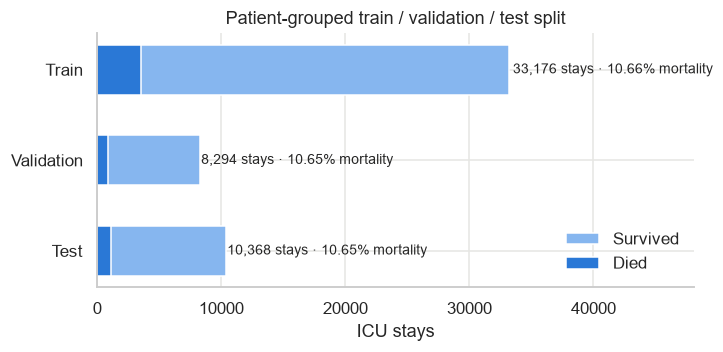

In [10]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(split_summary["set"], split_summary["stays"], color="#86b6ef", height=0.55, label="Survived")
ax.barh(split_summary["set"], split_summary["deaths"], color="#2a78d6", height=0.55, label="Died")
for i, r in split_summary.iterrows():
    ax.text(r["stays"] * 1.01, i, f'{r["stays"]:,} stays · {r["mortality_%"]:.2f}% mortality', va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, split_summary["stays"].max() * 1.45)
ax.set_xlabel("ICU stays"); ax.set_title("Patient-grouped train / validation / test split")
ax.legend(loc="lower right", frameon=False)
savefig("01_data_split")

The three sets have the same mortality rate (stratification worked) and no patient is shared between them
(grouping worked), so validation and test estimates are not inflated by patients seen during training.

### 2.4 Auxiliary raw table (aligned to the three sets)
The raw Part 1 table is joined to each set by `stay_id`. Only the columns listed here are loaded; none of them is
used as a model input.

In [11]:
SUBGROUP_COLS = ["gender", "age_band", "race_group", "insurance", "admission_group", "careunit_group", "anchor_year_group"]
SOFA_COLS = ["pf_ratio_min", "invasive_vent", "noninvasive_vent", "platelets_min", "bilirubin_max", "mbp_min",
             "vaso_dopamine", "vaso_dobutamine", "vaso_epinephrine", "vaso_norepinephrine", "vaso_phenylephrine",
             "vaso_vasopressin", "gcs_total_min", "gcs_eye_min", "gcs_motor_min", "gcs_verbal_min",
             "creatinine_max", "urine_output_24h"]


def base_column(feature):
    # raw column behind a processed feature, e.g. log_bun_max -> bun_max, ast_max_missing -> ast_max
    f = feature[4:] if feature.startswith("log_") else feature
    return f[:-8] if f.endswith("_missing") else f


raw_path = find_file("cohort_features_raw.parquet")
HAS_RAW = raw_path is not None
if HAS_RAW:
    import pyarrow.parquet as pq
    raw_names = set(pq.read_schema(raw_path).names)
    MISS_BASE = sorted({base_column(f) for f in FEATS_SEL if base_column(f) in raw_names
                        and not f.endswith("_count")} - set(SUBGROUP_COLS))
    wanted = [c for c in dict.fromkeys(SUBGROUP_COLS + SOFA_COLS + MISS_BASE) if c in raw_names]
    raw = pd.read_parquet(raw_path, columns=[ID] + wanted)
    if ID not in raw.columns:              # stay_id stored as the parquet index
        raw = raw.reset_index()
    raw = raw.drop_duplicates(ID).set_index(ID)
    raw_tr, raw_va, raw_te = (raw.reindex(d[ID].to_numpy()) for d in (train, val, test))
    assert raw_te.index.notna().all() and len(raw_te) == len(test)
    print(f"Raw table joined: {len(wanted)} auxiliary columns; "
          f"{len(MISS_BASE)} raw variables behind the 40 selected features")
else:
    print("cohort_features_raw.parquet not attached - SOFA baseline, subgroup, missing-data and temporal "
          "analyses will be skipped")

Raw table joined: 51 auxiliary columns; 32 raw variables behind the 40 selected features


## 3. Model selection and implementation

We compare five model families that cover the main approaches for tabular clinical data, from the most interpretable
to the most flexible:

| Model | Family | Why we include it |
|---|---|---|
| **Logistic Regression** (L2) | linear, generalised linear model | the reference model of clinical risk scores (APACHE, SAPS); interpretable coefficients; usually well calibrated |
| **Random Forest** | bagging of decision trees | captures non-linearity and interactions; robust to outliers; little tuning needed |
| **XGBoost** | gradient-boosted trees | state of the art on tabular data and in published MIMIC mortality models; GPU support |
| **LightGBM** | gradient-boosted trees (leaf-wise growth, histogram) | a second boosting implementation to test whether results depend on the library |
| **MLP** (multi-layer perceptron) | feed-forward neural network | the deep-learning approach; checks whether a neural model adds value on 40 engineered features |

All models use the **40 features selected in Part 1** (Section 5.3 tests the full 257-feature set).
**Logistic regression vs. XGBoost** is the core comparison pre-specified in our review protocol (hypothesis H3: the
gain of ML over logistic regression is small when both are tuned equally on the same cohort); the other three models
answer the course requirement to compare several approaches.
The factory function below builds each model from a dictionary of hyperparameters, so the same code is used for
default models, tuning, and the final pipeline.

### 3.1 Model factory

In [12]:
def make_model(name, params=None):
    # build an untrained model from a hyperparameter dictionary
    p = dict(params or {})
    if name == "LogReg":
        return LogisticRegression(C=p.get("C", 1.0), class_weight=p.get("class_weight"),
                                  max_iter=5000, random_state=SEED)
    if name == "RandomForest":
        return RandomForestClassifier(n_estimators=p.get("n_estimators", 300), max_depth=p.get("max_depth"),
                                      min_samples_leaf=p.get("min_samples_leaf", 1),
                                      max_features=p.get("max_features", "sqrt"),
                                      max_samples=p.get("max_samples"), class_weight=p.get("class_weight"),
                                      n_jobs=-1, random_state=SEED)
    if name == "XGBoost":
        return xgb.XGBClassifier(n_estimators=p.get("n_estimators", 300), learning_rate=p.get("learning_rate", 0.1),
                                 max_depth=p.get("max_depth", 6), min_child_weight=p.get("min_child_weight", 1),
                                 subsample=p.get("subsample", 1.0), colsample_bytree=p.get("colsample_bytree", 1.0),
                                 reg_lambda=p.get("reg_lambda", 1.0), reg_alpha=p.get("reg_alpha", 0.0),
                                 gamma=p.get("gamma", 0.0), scale_pos_weight=p.get("scale_pos_weight", 1.0),
                                 tree_method="hist", device="cuda" if GPU else "cpu",
                                 eval_metric="aucpr", n_jobs=-1, random_state=SEED, verbosity=0)
    if name == "LightGBM":
        return lgb.LGBMClassifier(n_estimators=p.get("n_estimators", 300), learning_rate=p.get("learning_rate", 0.1),
                                  num_leaves=p.get("num_leaves", 31), min_child_samples=p.get("min_child_samples", 20),
                                  subsample=p.get("subsample", 1.0), subsample_freq=1,
                                  colsample_bytree=p.get("colsample_bytree", 1.0),
                                  reg_lambda=p.get("reg_lambda", 0.0), reg_alpha=p.get("reg_alpha", 0.0),
                                  scale_pos_weight=p.get("scale_pos_weight", 1.0),
                                  n_jobs=-1, random_state=SEED, verbose=-1)
    if name == "MLP":
        layers = tuple(int(u) for u in str(p.get("hidden", "64")).split("-"))
        return MLPClassifier(hidden_layer_sizes=layers, alpha=p.get("alpha", 1e-4),
                             learning_rate_init=p.get("lr", 1e-3), batch_size=p.get("batch_size", 256),
                             early_stopping=True, validation_fraction=0.1, n_iter_no_change=10,
                             max_iter=300, random_state=SEED)
    raise ValueError(name)


DEFAULT_PARAMS = {m: {} for m in MODEL_NAMES}   # library defaults = "untuned" baseline

### 3.2 Published severity-score baseline: SOFA (first 24 h)
The protocol requires a *real* published score, not a "score-like" model, as a comparator (RQ5). We compute the
**Sequential Organ Failure Assessment (SOFA)** score (Vincent et al., 1996) from the worst first-24-h values in the raw
table:

| Organ system | Variable used | Points 1 / 2 / 3 / 4 |
|---|---|---|
| Respiration | PaO₂/FiO₂ minimum (+ ventilation) | < 400 / < 300 / < 200 ventilated / < 100 ventilated |
| Coagulation | platelets minimum (×10³/µL) | < 150 / < 100 / < 50 / < 20 |
| Liver | bilirubin maximum (mg/dL) | 1.2–1.9 / 2.0–5.9 / 6.0–11.9 / ≥ 12 |
| Cardiovascular | MAP minimum, vasopressors | MAP < 70 / dopamine or dobutamine / norepinephrine, epinephrine, phenylephrine or vasopressin |
| CNS | GCS total minimum | 13–14 / 10–12 / 6–9 / < 6 |
| Renal | creatinine maximum (mg/dL), 24-h urine | 1.2–1.9 / 2.0–3.4 / 3.5–4.9 or urine < 500 mL / ≥ 5.0 or urine < 200 mL |

**Deviations from the original score (stated for transparency):** vasopressor *doses* are not in the feature table,
so any norepinephrine/epinephrine use scores 3 (the dose-dependent 4 cannot be assigned); a missing component scores
0 (the usual convention: unmeasured = assumed normal). The score is turned into a probability with a one-variable
logistic regression fitted on the training set, then calibrated like every other model.

SOFA (train): median 5, IQR 2-10; AUROC of the raw score on the validation set 0.699


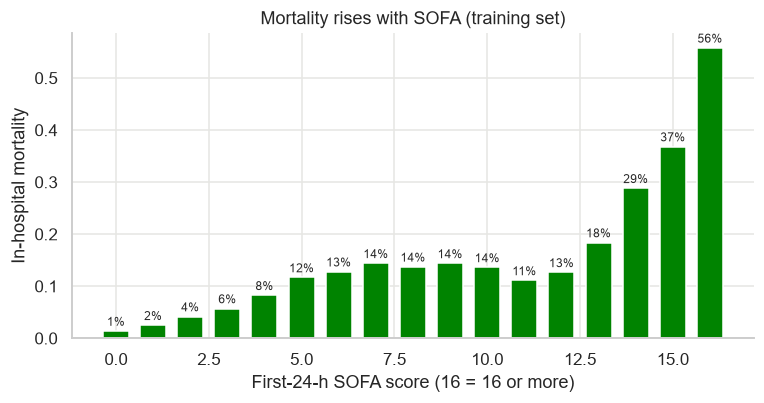

In [13]:
def sofa_score(r):
    # first-24-h SOFA from the raw Part 1 table (vectorised over a DataFrame)
    def bands(x, cuts):           # cuts in increasing order of severity -> points 1..4
        pts = np.zeros(len(x))
        for k, cond in enumerate(cuts, start=1):
            pts = np.where(cond(x).fillna(False).to_numpy(), k, pts)
        return pts

    vent = (r.get("invasive_vent", 0).fillna(0) > 0) | (r.get("noninvasive_vent", 0).fillna(0) > 0)
    pf = r["pf_ratio_min"]
    resp = bands(pf, [lambda v: v < 400, lambda v: v < 300])
    resp = np.where((pf < 200).fillna(False) & vent, 3, resp)
    resp = np.where((pf < 100).fillna(False) & vent, 4, resp)

    coag = bands(r["platelets_min"], [lambda v: v < 150, lambda v: v < 100, lambda v: v < 50, lambda v: v < 20])
    liver = bands(r["bilirubin_max"], [lambda v: v >= 1.2, lambda v: v >= 2.0, lambda v: v >= 6.0, lambda v: v >= 12.0])

    def any_of(cols):
        return np.any([r[c].fillna(0).to_numpy() > 0 for c in cols if c in r], axis=0)
    cardio = np.where((r["mbp_min"] < 70).fillna(False), 1, 0)
    cardio = np.where(any_of(["vaso_dopamine", "vaso_dobutamine"]), 2, cardio)
    cardio = np.where(any_of(["vaso_norepinephrine", "vaso_epinephrine", "vaso_phenylephrine", "vaso_vasopressin"]), 3, cardio)

    gcs = r["gcs_total_min"].copy()
    parts = r[["gcs_eye_min", "gcs_motor_min", "gcs_verbal_min"]].sum(axis=1, min_count=3)
    gcs = gcs.fillna(parts)
    cns = bands(gcs, [lambda v: v < 15, lambda v: v < 13, lambda v: v < 10, lambda v: v < 6])

    renal = bands(r["creatinine_max"], [lambda v: v >= 1.2, lambda v: v >= 2.0, lambda v: v >= 3.5, lambda v: v >= 5.0])
    urine = r["urine_output_24h"]
    renal = np.maximum(renal, np.where((urine < 500).fillna(False), 3, 0))
    renal = np.maximum(renal, np.where((urine < 200).fillna(False), 4, 0))
    comp = pd.DataFrame({"respiration": resp, "coagulation": coag, "liver": liver, "cardiovascular": cardio,
                         "cns": cns, "renal": renal}, index=r.index)
    comp["SOFA"] = comp.sum(axis=1)
    return comp


BASELINES = []
if HAS_RAW and set(SOFA_COLS) - {"noninvasive_vent", "vaso_phenylephrine", "vaso_vasopressin"} <= set(raw.columns):
    sofa_tr, sofa_va, sofa_te = (sofa_score(r) for r in (raw_tr, raw_va, raw_te))
    BASELINES = ["SOFA"]
    sofa_tab = (pd.DataFrame({"SOFA": sofa_tr["SOFA"].clip(upper=16).to_numpy(), "died": y_tr})
                .groupby("SOFA").agg(stays=("died", "size"), mortality=("died", "mean")))
    sofa_tab.to_csv(RES_DIR / "sofa_mortality_train.csv")
    print(f"SOFA (train): median {np.median(sofa_tr['SOFA']):.0f}, IQR "
          f"{np.percentile(sofa_tr['SOFA'], 25):.0f}-{np.percentile(sofa_tr['SOFA'], 75):.0f}; "
          f"AUROC of the raw score on the validation set {roc_auc_score(y_va, sofa_va['SOFA']):.3f}")

    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.bar(sofa_tab.index, sofa_tab["mortality"], color=PALETTE["SOFA"], width=0.7)
    for s, row in sofa_tab.iterrows():
        if row["stays"] >= 30:
            ax.text(s, row["mortality"] + 0.01, f'{100 * row["mortality"]:.0f}%', ha="center", fontsize=8)
    ax.set(xlabel="First-24-h SOFA score (16 = 16 or more)", ylabel="In-hospital mortality",
           title="Mortality rises with SOFA (training set)")
    savefig("02b_sofa_mortality")

## 4. Model training and hyperparameter tuning

### 4.1 Cross-validation design
Hyperparameters are tuned with **3-fold `StratifiedGroupKFold` cross-validation on the training set only**
(groups = patients). The objective is the mean **AUPRC** across folds, because with 10.7% positives AUPRC is more
sensitive than AUROC to how well the model finds the deaths; AUROC is recorded alongside.

In [14]:
cv_folds = list(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(X_tr, y_tr, g_tr))


def cv_score(name, params, X=None, y=None, folds=None):
    # mean AUPRC and AUROC across the grouped CV folds
    X = X_tr if X is None else X
    y = y_tr if y is None else y
    folds = cv_folds if folds is None else folds
    aps, aucs = [], []
    for f_tr, f_va in folds:
        model = make_model(name, params).fit(X.iloc[f_tr], y[f_tr])
        p = model.predict_proba(X.iloc[f_va])[:, 1]
        aps.append(average_precision_score(y[f_va], p)); aucs.append(roc_auc_score(y[f_va], p))
    return float(np.mean(aps)), float(np.mean(aucs)), float(np.std(aps))


print(f"{N_FOLDS} grouped folds; validation-fold sizes:", [len(v) for _, v in cv_folds])

3 grouped folds; validation-fold sizes: [11059, 11058, 11059]


### 4.2 Baseline: default hyperparameters
First, every model is trained with the library defaults. This is the reference point for measuring how much tuning
improves performance (Section 5.1).

In [15]:
baseline_rows = []
for name in MODEL_NAMES:
    t0 = time.time()
    ap, auc, sd = cv_score(name, DEFAULT_PARAMS[name])
    baseline_rows.append({"model": name, "cv_AUPRC": ap, "cv_AUPRC_sd": sd, "cv_AUROC": auc, "seconds": time.time() - t0})
    print(f"{name:<13} AUPRC {ap:.4f} ± {sd:.4f} | AUROC {auc:.4f} | {time.time() - t0:5.1f}s")
baseline_cv = pd.DataFrame(baseline_rows)
baseline_cv.to_csv(RES_DIR / "cv_baseline_default_params.csv", index=False)

LogReg        AUPRC 0.5047 ± 0.0101 | AUROC 0.8786 |   0.6s


RandomForest  AUPRC 0.5368 ± 0.0192 | AUROC 0.8843 |  27.3s


XGBoost       AUPRC 0.5354 ± 0.0130 | AUROC 0.8847 |  20.3s


LightGBM      AUPRC 0.5349 ± 0.0132 | AUROC 0.8852 |   8.9s


MLP           AUPRC 0.5381 ± 0.0217 | AUROC 0.8895 |  10.4s


### 4.3 Search spaces
Bayesian optimisation with **Optuna's TPE sampler** proposes new hyperparameters based on earlier trials, which finds
good settings with far fewer fits than a grid search. The number of trials per model reflects the size of its search
space and its training cost.

| Model | Hyperparameters searched |
|---|---|
| Logistic Regression | `C` (inverse L2 strength, 10⁻⁴–10², log scale) |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features`, `max_samples` |
| XGBoost | `n_estimators`, `learning_rate`, `max_depth`, `min_child_weight`, `subsample`, `colsample_bytree`, `reg_lambda`, `reg_alpha`, `gamma` |
| LightGBM | `n_estimators`, `learning_rate`, `num_leaves`, `min_child_samples`, `subsample`, `colsample_bytree`, `reg_lambda`, `reg_alpha` |
| MLP | hidden layers, `alpha` (L2), initial learning rate, batch size |

Class weighting is **not** tuned here (it changes probabilities, not ranking); it is tested separately in Section 5.2.

In [16]:
def search_space(name, t):
    if name == "LogReg":
        return {"C": t.suggest_float("C", 1e-4, 1e2, log=True)}
    if name == "RandomForest":
        return {"n_estimators": t.suggest_int("n_estimators", 200, 400, step=100),
                "max_depth": t.suggest_int("max_depth", 6, 30),
                "min_samples_leaf": t.suggest_int("min_samples_leaf", 1, 50, log=True),
                "max_features": t.suggest_categorical("max_features", ["sqrt", "log2", 0.3, 0.5]),
                "max_samples": t.suggest_float("max_samples", 0.5, 1.0)}
    if name == "XGBoost":
        return {"n_estimators": t.suggest_int("n_estimators", 200, 1000, step=100),
                "learning_rate": t.suggest_float("learning_rate", 0.01, 0.2, log=True),
                "max_depth": t.suggest_int("max_depth", 3, 9),
                "min_child_weight": t.suggest_float("min_child_weight", 1, 20, log=True),
                "subsample": t.suggest_float("subsample", 0.6, 1.0),
                "colsample_bytree": t.suggest_float("colsample_bytree", 0.4, 1.0),
                "reg_lambda": t.suggest_float("reg_lambda", 1e-2, 20, log=True),
                "reg_alpha": t.suggest_float("reg_alpha", 1e-3, 5, log=True),
                "gamma": t.suggest_float("gamma", 1e-3, 5, log=True)}
    if name == "LightGBM":
        return {"n_estimators": t.suggest_int("n_estimators", 200, 1000, step=100),
                "learning_rate": t.suggest_float("learning_rate", 0.01, 0.2, log=True),
                "num_leaves": t.suggest_int("num_leaves", 8, 128, log=True),
                "min_child_samples": t.suggest_int("min_child_samples", 10, 200, log=True),
                "subsample": t.suggest_float("subsample", 0.6, 1.0),
                "colsample_bytree": t.suggest_float("colsample_bytree", 0.4, 1.0),
                "reg_lambda": t.suggest_float("reg_lambda", 1e-3, 20, log=True),
                "reg_alpha": t.suggest_float("reg_alpha", 1e-3, 5, log=True)}
    if name == "MLP":
        return {"hidden": t.suggest_categorical("hidden", ["64", "128", "128-64", "256-128", "128-64-32"]),
                "alpha": t.suggest_float("alpha", 1e-5, 1e-1, log=True),
                "lr": t.suggest_float("lr", 1e-4, 1e-2, log=True),
                "batch_size": t.suggest_categorical("batch_size", [128, 256, 512])}
    raise ValueError(name)


class RandomTrial:
    # minimal stand-in for an Optuna trial, used only when Optuna is not installed (random search)
    def __init__(self, rng):
        self.rng, self.params = rng, {}

    def suggest_float(self, n, lo, hi, log=False):
        v = float(np.exp(self.rng.uniform(np.log(lo), np.log(hi)))) if log else float(self.rng.uniform(lo, hi))
        self.params[n] = v; return v

    def suggest_int(self, n, lo, hi, step=1, log=False):
        v = int(round(np.exp(self.rng.uniform(np.log(lo), np.log(hi))))) if log else int(self.rng.choice(np.arange(lo, hi + 1, step)))
        self.params[n] = v; return v

    def suggest_categorical(self, n, choices):
        v = choices[int(self.rng.integers(len(choices)))]
        self.params[n] = v; return v

### 4.4 Run the tuning
Each trial trains the model on 2 folds and scores the 3rd, three times. Results of every trial are stored so the
optimisation history can be plotted.

In [17]:
best_params, tuning_history, tuning_rows = {}, {}, []

for name in MODEL_NAMES:
    t0 = time.time()
    history = []

    def objective(trial):
        params = search_space(name, trial)
        ap, auc, sd = cv_score(name, params)
        history.append({"trial": len(history), "cv_AUPRC": ap, "cv_AUROC": auc, **params})
        return ap

    if HAS_OPTUNA:
        study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
        study.optimize(objective, n_trials=N_TRIALS[name])
        best = study.best_params
    else:
        rng = np.random.default_rng(SEED)
        for _ in range(N_TRIALS[name]):
            objective(RandomTrial(rng))
        best = {k: v for k, v in max(history, key=lambda h: h["cv_AUPRC"]).items()
                if k not in ("trial", "cv_AUPRC", "cv_AUROC")}

    hist = pd.DataFrame(history)
    b = hist.loc[hist["cv_AUPRC"].idxmax()]
    best_params[name], tuning_history[name] = best, hist
    tuning_rows.append({"model": name, "trials": len(hist), "cv_AUPRC": b["cv_AUPRC"], "cv_AUROC": b["cv_AUROC"],
                        "minutes": (time.time() - t0) / 60, "best_params": json.dumps(best)})
    print(f"{name:<13} best CV AUPRC {b['cv_AUPRC']:.4f} | AUROC {b['cv_AUROC']:.4f} | "
          f"{len(hist)} trials in {(time.time() - t0) / 60:.1f} min")

tuning_summary = pd.DataFrame(tuning_rows)
tuning_summary.to_csv(RES_DIR / "tuning_best_params.csv", index=False)
json.dump(best_params, open(RES_DIR / "best_params.json", "w"), indent=2)

LogReg        best CV AUPRC 0.5048 | AUROC 0.8790 | 15 trials in 0.1 min


RandomForest  best CV AUPRC 0.5392 | AUROC 0.8846 | 8 trials in 2.2 min


XGBoost       best CV AUPRC 0.5602 | AUROC 0.8961 | 25 trials in 13.7 min


LightGBM      best CV AUPRC 0.5579 | AUROC 0.8953 | 20 trials in 8.8 min


MLP           best CV AUPRC 0.5432 | AUROC 0.8896 | 6 trials in 1.8 min


In [18]:
for name in MODEL_NAMES:
    print(f"\n{name}:")
    for k, v in best_params[name].items():
        print(f"   {k:<18} {v:.5g}" if isinstance(v, float) else f"   {k:<18} {v}")


LogReg:
   C                  0.15917

RandomForest:
   n_estimators       200
   max_depth          18
   min_samples_leaf   1
   max_features       sqrt
   max_samples        0.76003

XGBoost:
   n_estimators       600
   learning_rate      0.010715
   max_depth          8
   min_child_weight   13.084
   subsample          0.71844
   colsample_bytree   0.53401
   reg_lambda         0.11165
   reg_alpha          0.028447
   gamma              0.093017

LightGBM:
   n_estimators       700
   learning_rate      0.010973
   num_leaves         32
   min_child_samples  86
   subsample          0.81526
   colsample_bytree   0.7659
   reg_lambda         1.2941
   reg_alpha          0.52647

MLP:
   hidden             128
   alpha              5.4152e-05
   lr                 0.00040596
   batch_size         128


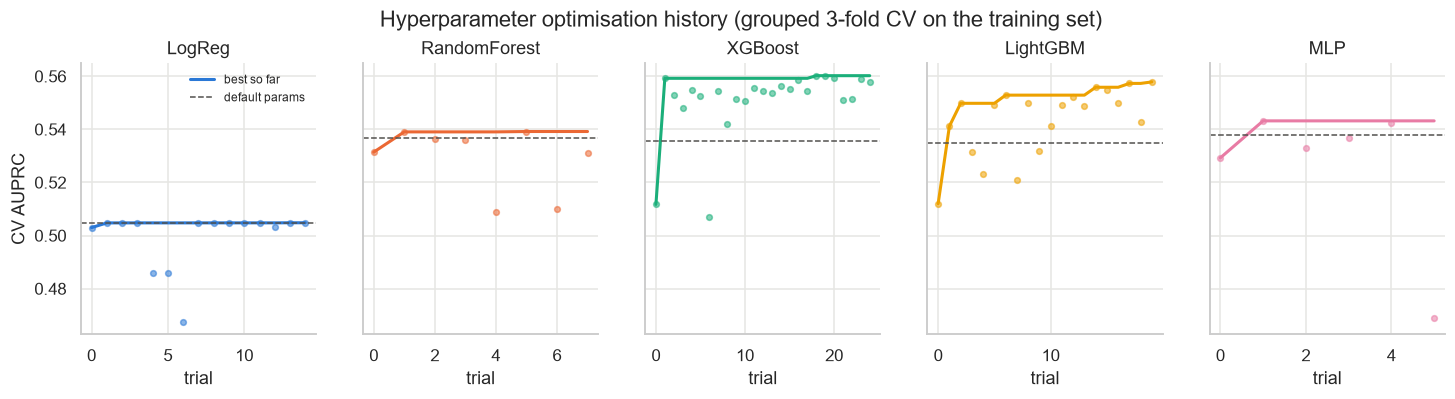

In [19]:
fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(16, 3.2), sharey=True)
for ax, name in zip(axes, MODEL_NAMES):
    h = tuning_history[name]
    ax.scatter(h["trial"], h["cv_AUPRC"], s=14, color=PALETTE[name], alpha=0.55)
    ax.plot(h["trial"], h["cv_AUPRC"].cummax(), color=PALETTE[name], lw=2, label="best so far")
    ax.axhline(baseline_cv.set_index("model").loc[name, "cv_AUPRC"], color="#52514e", ls="--", lw=1, label="default params")
    ax.set_title(name); ax.set_xlabel("trial")
axes[0].set_ylabel("CV AUPRC"); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Hyperparameter optimisation history (grouped 3-fold CV on the training set)", y=1.03)
savefig("02_tuning_history")

### 4.5 Train the tuned models
Each model is refitted with its best hyperparameters on the **whole training set** and then predicts the validation
and test sets. Training time is recorded for the comparison. Test predictions are stored now but **not looked at**
until Section 7.

In [20]:
models, p_val_raw, p_test_raw, train_seconds = {}, {}, {}, {}
for name in MODEL_NAMES:
    t0 = time.time()
    models[name] = make_model(name, best_params[name]).fit(X_tr, y_tr)
    train_seconds[name] = time.time() - t0
    p_val_raw[name] = models[name].predict_proba(X_va)[:, 1]
    p_test_raw[name] = models[name].predict_proba(X_te)[:, 1]
    print(f"{name:<13} trained in {train_seconds[name]:6.1f}s | validation AUPRC "
          f"{average_precision_score(y_va, p_val_raw[name]):.4f} | AUROC {roc_auc_score(y_va, p_val_raw[name]):.4f}")

if "SOFA" in BASELINES:   # one-variable logistic model on the SOFA total, fitted on the training set
    t0 = time.time()
    models["SOFA"] = LogisticRegression(max_iter=1000).fit(sofa_tr[["SOFA"]], y_tr)
    train_seconds["SOFA"] = time.time() - t0
    p_val_raw["SOFA"] = models["SOFA"].predict_proba(sofa_va[["SOFA"]])[:, 1]
    p_test_raw["SOFA"] = models["SOFA"].predict_proba(sofa_te[["SOFA"]])[:, 1]
    print(f"{'SOFA':<13} (baseline)       | validation AUPRC {average_precision_score(y_va, p_val_raw['SOFA']):.4f} "
          f"| AUROC {roc_auc_score(y_va, p_val_raw['SOFA']):.4f}")

LogReg        trained in    0.2s | validation AUPRC 0.4880 | AUROC 0.8752


RandomForest  trained in    5.7s | validation AUPRC 0.5351 | AUROC 0.8868


XGBoost       trained in   11.6s | validation AUPRC 0.5559 | AUROC 0.8961


LightGBM      trained in   12.5s | validation AUPRC 0.5521 | AUROC 0.8944


MLP           trained in   10.2s | validation AUPRC 0.5432 | AUROC 0.8903
SOFA          (baseline)       | validation AUPRC 0.2420 | AUROC 0.6994


## 5. Model optimisation and performance improvement

Five levers are tested, each judged on **training-CV or validation data only**:

1. hyperparameter tuning vs. defaults;
2. class weighting for the 8.4 : 1 imbalance;
3. 40 selected features vs. all 257;
4. post-hoc probability calibration (Platt scaling, isotonic regression);
5. a soft-voting ensemble of the best models;

and finally the **decision threshold** is chosen.

### 5.1 Effect of hyperparameter tuning

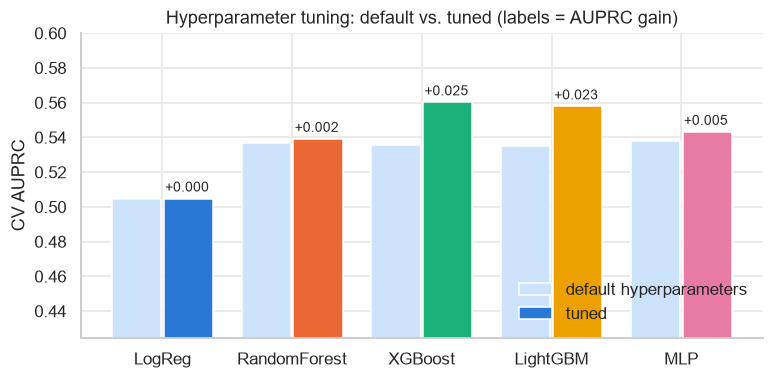

,model,cv_AUPRC_default,cv_AUROC_default,cv_AUPRC_tuned,cv_AUROC_tuned,AUPRC_gain,AUROC_gain
0,LogReg,0.5047,0.8786,0.5048,0.8790,0.0001,0.0003
1,RandomForest,0.5368,0.8843,0.5392,0.8846,0.0024,0.0002
2,XGBoost,0.5354,0.8847,0.5602,0.8961,0.0248,0.0113
3,LightGBM,0.5349,0.8852,0.5579,0.8953,0.0229,0.0102
4,MLP,0.5381,0.8895,0.5432,0.8896,0.0051,0.0000


In [21]:
tuning_gain = baseline_cv[["model", "cv_AUPRC", "cv_AUROC"]].merge(
    tuning_summary[["model", "cv_AUPRC", "cv_AUROC"]], on="model", suffixes=("_default", "_tuned"))
tuning_gain["AUPRC_gain"] = tuning_gain["cv_AUPRC_tuned"] - tuning_gain["cv_AUPRC_default"]
tuning_gain["AUROC_gain"] = tuning_gain["cv_AUROC_tuned"] - tuning_gain["cv_AUROC_default"]
tuning_gain.to_csv(RES_DIR / "cv_default_vs_tuned.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(MODEL_NAMES)); w = 0.38
ax.bar(x - w / 2 - 0.01, tuning_gain["cv_AUPRC_default"], w, color="#cde2fb", label="default hyperparameters")
ax.bar(x + w / 2 + 0.01, tuning_gain["cv_AUPRC_tuned"], w, color=[PALETTE[m] for m in MODEL_NAMES], label="tuned")
for i, r in tuning_gain.iterrows():
    ax.text(i + w / 2, r["cv_AUPRC_tuned"] + 0.004, f'{r["AUPRC_gain"]:+.3f}', ha="center", fontsize=9)
ax.set_xticks(x, MODEL_NAMES); ax.set_ylabel("CV AUPRC")
ax.set_ylim(max(0, tuning_gain[["cv_AUPRC_default", "cv_AUPRC_tuned"]].min().min() - 0.08),
            tuning_gain["cv_AUPRC_tuned"].max() + 0.04)
ax.axhline(y_tr.mean(), color="#52514e", ls=":", lw=1); ax.legend(frameon=False, loc="lower right")
ax.set_title("Hyperparameter tuning: default vs. tuned (labels = AUPRC gain)")
savefig("03_tuning_gain")
tuning_gain

### 5.2 Class imbalance: unweighted vs. class-weighted training
Re-weighting the minority class (`class_weight="balanced"` for logistic regression, `scale_pos_weight = n_neg / n_pos`
for XGBoost) is a common fix for imbalance. It can increase sensitivity at a 0.5 threshold, but it **inflates the
predicted probabilities**. We compare both on the validation set.

In [22]:
pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()
imb_rows = []
for name, wparam in [("LogReg", {"class_weight": "balanced"}), ("XGBoost", {"scale_pos_weight": pos_weight}),
                     ("LightGBM", {"scale_pos_weight": pos_weight})]:
    for label, extra in [("unweighted", {}), ("weighted", wparam)]:
        m = models[name] if label == "unweighted" else make_model(name, {**best_params[name], **extra}).fit(X_tr, y_tr)
        p = m.predict_proba(X_va)[:, 1]
        e = evaluate(y_va, p, 0.5)
        imb_rows.append({"model": name, "training": label, "AUROC": e["AUROC"], "AUPRC": e["AUPRC"], "Brier": e["Brier"],
                         "ECE": e["ECE"], "mean_predicted_risk": p.mean(), "observed_rate": y_va.mean(),
                         "sensitivity@0.5": e["Sensitivity"]})
imbalance = pd.DataFrame(imb_rows)
imbalance.to_csv(RES_DIR / "val_class_weighting.csv", index=False)
print(f"positive-class weight = {pos_weight:.2f}")
imbalance

positive-class weight = 8.39


,model,training,AUROC,AUPRC,Brier,ECE,mean_predicted_risk,observed_rate,sensitivity@0.5
0,LogReg,unweighted,0.8752,0.4880,0.0713,0.0133,0.1048,0.1065,0.2559
1,LogReg,weighted,0.8766,0.4866,0.1402,0.2181,0.3245,0.1065,0.7928
2,XGBoost,unweighted,0.8961,0.5559,0.0657,0.0076,0.1033,0.1065,0.3182
3,XGBoost,weighted,0.8938,0.5478,0.1056,0.1525,0.2590,0.1065,0.7429
4,LightGBM,unweighted,0.8944,0.5521,0.0659,0.0066,0.1032,0.1065,0.3386
5,LightGBM,weighted,0.8938,0.5470,0.1173,0.1655,0.2720,0.1065,0.7939


**Reading the table.** Weighting barely changes AUROC/AUPRC (ranking), raises sensitivity at the 0.5 cut-off, but
the mean predicted risk moves far above the observed mortality, so Brier score and ECE get worse. Because this project
is about *calibrated* risk estimates, we keep **unweighted training** and handle the imbalance by choosing the decision
threshold on validation data (Section 5.6) instead of re-weighting.

### 5.3 Feature set: 40 selected vs. all 257 features
Part 1 reduced 257 features to 40. Here we check what that costs: the tuned XGBoost and logistic regression are
retrained on all 257 features and compared on the validation set.

In [23]:
fs_rows = []
for name in ["LogReg", "XGBoost"]:
    for label, feats in [("40 selected", FEATS_SEL), ("257 all", FEATS_ALL)]:
        if label == "40 selected":
            p = p_val_raw[name]
        else:
            p = make_model(name, best_params[name]).fit(train[feats], y_tr).predict_proba(val[feats])[:, 1]
        e = evaluate(y_va, p, 0.5)
        fs_rows.append({"model": name, "features": label, "n_features": len(feats), "AUROC": e["AUROC"],
                        "AUPRC": e["AUPRC"], "Brier": e["Brier"]})
feature_sets = pd.DataFrame(fs_rows)
feature_sets.to_csv(RES_DIR / "val_feature_sets.csv", index=False)
feature_sets

,model,features,n_features,AUROC,AUPRC,Brier
0,LogReg,40 selected,40,0.8752,0.4880,0.0713
1,LogReg,257 all,257,0.8932,0.5539,0.0661
2,XGBoost,40 selected,40,0.8961,0.5559,0.0657
3,XGBoost,257 all,257,0.9087,0.6049,0.0622


The full feature set improves validation AUPRC noticeably (by roughly 0.05-0.07 in this run), so the 40-feature models trade some discrimination for parsimony: 40 features are easier to collect, explain and validate externally, and they are the pre-specified feature set of our protocol.
We keep the **40-feature models** as the main analysis and report this trade-off explicitly.

### 5.4 Probability calibration
Tree ensembles and neural networks often produce probabilities that are too extreme or too compressed. We compare
three options for every model:

* **none** — raw model output;
* **Platt scaling** — logistic regression on logit(p);
* **isotonic regression** — a monotone, non-parametric mapping.

**Isotonic regression is the pre-specified method** (fixed in our review protocol *before* any results were seen,
to avoid choosing the calibration that happens to look best). Platt scaling and "none" are reported alongside as a
sensitivity analysis only. All three are scored by **5-fold cross-validation inside the validation set** (each
calibrator is fitted on 4/5 of the validation predictions and scored on the remaining 1/5). This yields
*out-of-fold calibrated validation predictions*, used later for an honest choice of ensemble, threshold and final
model. The isotonic calibrator is then refitted on the whole validation set and applied unchanged to the test set.

In [24]:
class IdentityCalibrator:
    name = "none"
    def fit(self, p, y): return self
    def predict(self, p): return np.asarray(p, float)


class PlattCalibrator:
    name = "platt"
    def fit(self, p, y):
        self.lr = LogisticRegression(C=1e6, max_iter=1000).fit(_logit(p).reshape(-1, 1), y); return self
    def predict(self, p): return self.lr.predict_proba(_logit(p).reshape(-1, 1))[:, 1]


class IsotonicCalibrator:
    name = "isotonic"
    def fit(self, p, y):
        self.iso = IsotonicRegression(out_of_bounds="clip", y_min=1e-4, y_max=1 - 1e-4).fit(p, y); return self
    def predict(self, p): return self.iso.predict(np.asarray(p, float))


CALIBRATORS = {"none": IdentityCalibrator, "platt": PlattCalibrator, "isotonic": IsotonicCalibrator}
cal_folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(np.zeros(len(y_va)), y_va))


def oof_calibrated(p, method):
    # out-of-fold calibrated validation predictions
    out = np.zeros_like(p, dtype=float)
    for f_fit, f_eval in cal_folds:
        out[f_eval] = CALIBRATORS[method]().fit(p[f_fit], y_va[f_fit]).predict(p[f_eval])
    return out


cal_rows, cal_choice, p_val_oof, calibrators = [], {}, {}, {}
for name in MODEL_NAMES + BASELINES:
    oof = {}
    for method in CALIBRATORS:
        p_oof = oof_calibrated(p_val_raw[name], method)
        s, i = calibration_slope_intercept(y_va, p_oof)
        oof[method] = p_oof
        cal_rows.append({"model": name, "calibration": method, "Brier": brier_score_loss(y_va, p_oof),
                         "ECE": expected_calibration_error(y_va, p_oof, n_bins=N_CAL_BINS), "slope": s, "intercept": i,
                         "AUPRC": average_precision_score(y_va, p_oof)})
    cal_choice[name] = CAL_METHOD                                  # pre-specified, not chosen on the data
    p_val_oof[name] = oof[CAL_METHOD]
    calibrators[name] = CALIBRATORS[CAL_METHOD]().fit(p_val_raw[name], y_va)

calibration_val = pd.DataFrame(cal_rows)
calibration_val["pre_specified"] = calibration_val["calibration"] == CAL_METHOD
best_by_brier = calibration_val.loc[calibration_val.groupby("model")["Brier"].idxmin(), ["model", "calibration"]]
calibration_val.to_csv(RES_DIR / "val_calibration_methods.csv", index=False)
print(f"Pre-specified calibration for all models: {CAL_METHOD}")
print("Sensitivity check - method with the lowest out-of-fold Brier per model:",
      dict(zip(best_by_brier["model"], best_by_brier["calibration"])))
calibration_val.pivot(index="model", columns="calibration", values=["Brier", "ECE", "slope"]).round(4)

Pre-specified calibration for all models: isotonic
Sensitivity check - method with the lowest out-of-fold Brier per model: {'LightGBM': 'none', 'LogReg': 'isotonic', 'MLP': 'platt', 'RandomForest': 'platt', 'SOFA': 'isotonic', 'XGBoost': 'platt'}


Brier                    ECE                  slope              
calibration  isotonic   none  platt isotonic   none  platt isotonic   none  platt
model                                                                            
LightGBM       0.0663 0.0659 0.0659   0.0058 0.0066 0.0064   0.9484 1.0084 0.9991
LogReg         0.0709 0.0713 0.0713   0.0045 0.0133 0.0116   0.9478 0.9728 0.9970
MLP            0.0668 0.0670 0.0666   0.0045 0.0127 0.0061   0.9533 0.8831 0.9992
RandomForest   0.0675 0.0673 0.0671   0.0052 0.0092 0.0045   0.9511 1.1237 0.9996
SOFA           0.0877 0.0894 0.0895   0.0055 0.0260 0.0253   0.9603 1.0166 0.9961
XGBoost        0.0660 0.0657 0.0657   0.0039 0.0076 0.0052   0.9476 1.0472 0.9989

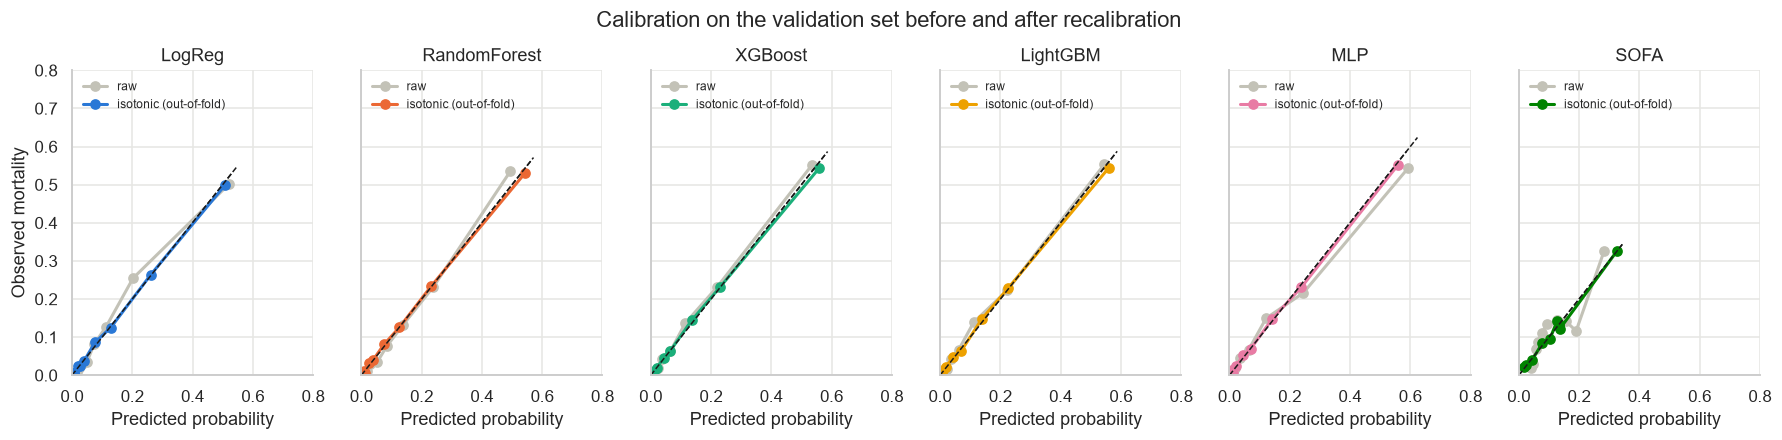

In [25]:
CAL_PANELS = MODEL_NAMES + BASELINES
fig, axes = plt.subplots(1, len(CAL_PANELS), figsize=(3.3 * len(CAL_PANELS), 3.6), sharey=True)
for ax, name in zip(axes, CAL_PANELS):
    plot_calibration(ax, y_va, p_val_raw[name], label="raw")
    plot_calibration(ax, y_va, p_val_oof[name], label=f"{cal_choice[name]} (out-of-fold)")
    ax.lines[0].set_color("#c3c2b7"); ax.lines[2].set_color(PALETTE[name])
    ax.set_title(name); ax.set_xlim(0, 0.8); ax.set_ylim(0, 0.8)
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    if ax is not axes[0]:
        ax.set_ylabel("")
fig.suptitle("Calibration on the validation set before and after recalibration", y=1.03)
savefig("04_calibration_validation")

### 5.5 Ensemble of the best models
A soft-voting ensemble averages the calibrated probabilities of the **three best models by validation AUPRC**
(computed on the out-of-fold calibrated predictions). It is accepted only if it beats the best single model by a
meaningful margin (≥ 0.005 AUPRC); otherwise the simpler single model is preferred.

In [26]:
val_rank = pd.DataFrame({
    "model": MODEL_NAMES,
    "val_AUPRC": [average_precision_score(y_va, p_val_oof[m]) for m in MODEL_NAMES],
    "val_AUROC": [roc_auc_score(y_va, p_val_oof[m]) for m in MODEL_NAMES],
    "val_Brier": [brier_score_loss(y_va, p_val_oof[m]) for m in MODEL_NAMES],
    "val_ECE": [expected_calibration_error(y_va, p_val_oof[m]) for m in MODEL_NAMES],
}).sort_values("val_AUPRC", ascending=False).reset_index(drop=True)

ENSEMBLE_MEMBERS = val_rank["model"].head(3).tolist()
p_val_oof["Ensemble"] = np.mean([p_val_oof[m] for m in ENSEMBLE_MEMBERS], axis=0)
ens = {"model": "Ensemble", "val_AUPRC": average_precision_score(y_va, p_val_oof["Ensemble"]),
       "val_AUROC": roc_auc_score(y_va, p_val_oof["Ensemble"]), "val_Brier": brier_score_loss(y_va, p_val_oof["Ensemble"]),
       "val_ECE": expected_calibration_error(y_va, p_val_oof["Ensemble"])}
val_rank = pd.concat([val_rank, pd.DataFrame([ens])]).sort_values("val_AUPRC", ascending=False).reset_index(drop=True)
val_rank.to_csv(RES_DIR / "val_model_ranking.csv", index=False)
print("Ensemble members:", ENSEMBLE_MEMBERS)
val_rank

Ensemble members: ['XGBoost', 'LightGBM', 'MLP']


,model,val_AUPRC,val_AUROC,val_Brier,val_ECE
0,Ensemble,0.5530,0.8950,0.0656,0.0025
1,XGBoost,0.5383,0.8923,0.0660,0.0039
2,LightGBM,0.5335,0.8915,0.0663,0.0058
3,MLP,0.5293,0.8871,0.0668,0.0045
4,RandomForest,0.5220,0.8835,0.0675,0.0052
5,LogReg,0.4728,0.8718,0.0709,0.0045


## 6. Final model selection

**Rule (fixed before looking at the test set):** choose the candidate with the highest validation AUPRC on
out-of-fold calibrated predictions; the ensemble must beat the best single model by ≥ 0.005 AUPRC to be chosen;
ties (< 0.002 AUPRC) are broken by the lower Brier score.

### 6.1 Apply the rule

In [27]:
singles = val_rank[val_rank["model"] != "Ensemble"].reset_index(drop=True)
best_single = singles.iloc[0]
close = singles[singles["val_AUPRC"] >= best_single["val_AUPRC"] - 0.002]
best_single = close.sort_values("val_Brier").iloc[0]
ens_row = val_rank.set_index("model").loc["Ensemble"]

if ens_row["val_AUPRC"] >= best_single["val_AUPRC"] + 0.005:
    FINAL_NAME, FINAL_MEMBERS = "Ensemble", ENSEMBLE_MEMBERS
else:
    FINAL_NAME, FINAL_MEMBERS = best_single["model"], [best_single["model"]]

print(f"Best single model : {best_single['model']} (val AUPRC {best_single['val_AUPRC']:.4f})")
print(f"Ensemble          : {ENSEMBLE_MEMBERS} (val AUPRC {ens_row['val_AUPRC']:.4f})")
print(f"==> FINAL MODEL   : {FINAL_NAME}  (members: {FINAL_MEMBERS}; calibration: "
      f"{ {m: cal_choice[m] for m in FINAL_MEMBERS} })")

Best single model : XGBoost (val AUPRC 0.5383)
Ensemble          : ['XGBoost', 'LightGBM', 'MLP'] (val AUPRC 0.5530)
==> FINAL MODEL   : Ensemble  (members: ['XGBoost', 'LightGBM', 'MLP']; calibration: {'XGBoost': 'isotonic', 'LightGBM': 'isotonic', 'MLP': 'isotonic'})


### 6.2 Decision threshold
A probability becomes an alarm ("high risk") at a threshold. The default 0.5 is inappropriate for a 10.7% outcome.
Two thresholds are chosen on the final model's **out-of-fold calibrated validation predictions**:

* **Youden's J** — maximises sensitivity + specificity − 1 (balanced screening);
* **Sensitivity ≥ 0.80** — the highest threshold that still catches 80% of deaths (early-warning use).

The Youden threshold is the primary operating point; both are reported on the test set.

In [28]:
p_val_final = p_val_oof[FINAL_NAME]
THRESHOLDS = {"youden": youden_threshold(y_va, p_val_final),
              "sens80": threshold_for_sensitivity(y_va, p_val_final, 0.80)}
THRESHOLD = THRESHOLDS["youden"]
model_thresholds = {m: youden_threshold(y_va, p_val_oof[m]) for m in MODEL_NAMES + BASELINES + ["Ensemble"]}
for k, t in THRESHOLDS.items():
    e = evaluate(y_va, p_val_final, t)
    print(f"{k:<7} threshold {t:.4f} | validation sensitivity {e['Sensitivity']:.3f} "
          f"specificity {e['Specificity']:.3f} PPV {e['PPV']:.3f}")

youden  threshold 0.1245 | validation sensitivity 0.823 specificity 0.806 PPV 0.336
sens80  threshold 0.1352 | validation sensitivity 0.802 specificity 0.819 PPV 0.346


## 7. Test-set evaluation

The test set (10,368 stays, never used so far) is evaluated **once**, for every candidate, with the calibrators and
thresholds fixed on validation data. Every metric gets a **95% percentile-bootstrap confidence interval**
(500 resamples).

In [29]:
p_test = {m: calibrators[m].predict(p_test_raw[m]) for m in MODEL_NAMES + BASELINES}
p_test["Ensemble"] = np.mean([p_test[m] for m in ENSEMBLE_MEMBERS], axis=0)
CANDIDATES = MODEL_NAMES + BASELINES + ["Ensemble"]

ci_tables, rows = {}, []
for m in CANDIDATES:
    ci = bootstrap_ci(y_te, p_test[m], model_thresholds[m], n_boot=N_BOOT, seed=SEED)
    ci_tables[m] = ci
    row = {"model": m}
    for metric in ["AUROC", "AUPRC", "Brier", "ECE", "Cal_slope", "Cal_intercept", "Sensitivity", "Specificity", "PPV", "F1"]:
        row[metric], row[f"{metric}_lo"], row[f"{metric}_hi"] = ci.loc[metric, ["estimate", "ci_low", "ci_high"]]
        row[f"{metric}_fmt"] = ci.loc[metric, "formatted"]
    row["threshold"] = model_thresholds[m]
    rows.append(row)
test_results = pd.DataFrame(rows)
test_results.to_csv(RES_DIR / "test_model_comparison.csv", index=False)

show = ["model"] + [f"{k}_fmt" for k in ["AUROC", "AUPRC", "Brier", "ECE", "Cal_slope", "Sensitivity", "Specificity"]]
test_results[show].rename(columns=lambda c: c.replace("_fmt", "")).set_index("model")

,AUROC,AUPRC,Brier,ECE,Cal_slope,Sensitivity,Specificity
model,,,,,,,
LogReg,0.869 (0.859–0.878),0.471 (0.443–0.498),0.071 (0.068–0.074),0.006 (0.004–0.011),0.957 (0.907–1.008),0.806 (0.785–0.831),0.786 (0.778–0.794)
RandomForest,0.882 (0.872–0.891),0.521 (0.490–0.548),0.068 (0.064–0.071),0.005 (0.003–0.010),0.976 (0.926–1.027),0.801 (0.777–0.824),0.797 (0.789–0.805)
XGBoost,0.890 (0.882–0.898),0.534 (0.503–0.560),0.066 (0.063–0.070),0.002 (0.003–0.009),0.958 (0.907–1.010),0.860 (0.839–0.880),0.765 (0.756–0.773)
LightGBM,0.889 (0.881–0.897),0.533 (0.502–0.560),0.067 (0.063–0.070),0.004 (0.003–0.010),0.965 (0.913–1.017),0.841 (0.819–0.864),0.783 (0.774–0.792)
MLP,0.888 (0.879–0.896),0.520 (0.490–0.546),0.067 (0.064–0.070),0.004 (0.003–0.010),0.979 (0.929–1.028),0.843 (0.822–0.866),0.776 (0.768–0.784)
SOFA,0.702 (0.687–0.717),0.229 (0.209–0.250),0.088 (0.084–0.092),0.004 (0.003–0.011),0.974 (0.896–1.060),0.825 (0.801–0.846),0.472 (0.463–0.483)
Ensemble,0.892 (0.884–0.900),0.559 (0.527–0.585),0.066 (0.063–0.069),0.003 (0.003–0.009),1.014 (0.964–1.068),0.822 (0.801–0.843),0.800 (0.792–0.809)


### 7.1 Calibration on the test set: raw vs. calibrated

In [30]:
rows = []
for m in MODEL_NAMES:
    for label, p in [("raw", p_test_raw[m]), (f"calibrated ({cal_choice[m]})", p_test[m])]:
        s, i = calibration_slope_intercept(y_te, p)
        rows.append({"model": m, "probabilities": label, "Brier": brier_score_loss(y_te, p),
                     "ECE": expected_calibration_error(y_te, p), "slope": s, "intercept": i,
                     "mean_pred": p.mean(), "observed": y_te.mean()})
calibration_test = pd.DataFrame(rows)
calibration_test.to_csv(RES_DIR / "test_calibration_raw_vs_calibrated.csv", index=False)
calibration_test

,model,probabilities,Brier,ECE,slope,intercept,mean_pred,observed
0,LogReg,raw,0.0711,0.0118,0.9732,0.0206,0.1051,0.1065
1,LogReg,calibrated (isotonic),0.0709,0.0057,0.9571,-0.0129,0.1074,0.1065
2,RandomForest,raw,0.0679,0.0090,1.1192,-0.0112,0.1073,0.1065
3,RandomForest,calibrated (isotonic),0.0676,0.0046,0.9755,0.0033,0.1063,0.1065
4,XGBoost,raw,0.0661,0.0073,1.0503,0.0551,0.1028,0.1065
5,XGBoost,calibrated (isotonic),0.0665,0.0020,0.9584,0.0071,0.1060,0.1065
6,LightGBM,raw,0.0663,0.0061,1.0111,0.0640,0.1023,0.1065
7,LightGBM,calibrated (isotonic),0.0665,0.0041,0.9653,0.0105,0.1058,0.1065
8,MLP,raw,0.0671,0.0115,0.8900,-0.0352,0.1087,0.1065
9,MLP,calibrated (isotonic),0.0670,0.0039,0.9786,0.0171,0.1053,0.1065


### 7.2 Statistical comparison of AUROCs (DeLong test)
The paired DeLong test checks whether the final model's AUROC differs from each other candidate's on the same
test patients.

In [31]:
rows = []
for m in CANDIDATES:
    if m == FINAL_NAME:
        continue
    d = delong_test(y_te, p_test[FINAL_NAME], p_test[m])
    rows.append({"comparison": f"{FINAL_NAME} vs {m}", "AUROC_final": d["AUROC_1"], "AUROC_other": d["AUROC_2"],
                 "difference": d["diff"], "z": d["z"], "p_value": d["p_value"],
                 "significant_0.05": d["p_value"] < 0.05})
delong = pd.DataFrame(rows)
delong.to_csv(RES_DIR / "test_delong.csv", index=False)
delong

,comparison,AUROC_final,AUROC_other,difference,z,p_value,significant_0.05
0,Ensemble vs LogReg,0.8925,0.8685,0.0239,9.7940,0.0000,True
1,Ensemble vs RandomForest,0.8925,0.8820,0.0105,5.4234,0.0000,True
2,Ensemble vs XGBoost,0.8925,0.8902,0.0023,3.0600,0.0022,True
3,Ensemble vs LightGBM,0.8925,0.8893,0.0032,3.9815,0.0001,True
4,Ensemble vs MLP,0.8925,0.8878,0.0046,3.9110,0.0001,True
5,Ensemble vs SOFA,0.8925,0.7022,0.1903,27.5055,0.0000,True


### 7.3 Final model at both operating points

In [32]:
op_rows = []
for k, t in THRESHOLDS.items():
    e = evaluate(y_te, p_test[FINAL_NAME], t)
    pred = (p_test[FINAL_NAME] >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    op_rows.append({"operating_point": k, "threshold": t, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                    "sensitivity": e["Sensitivity"], "specificity": e["Specificity"], "PPV": e["PPV"],
                    "NPV": e["NPV"], "F1": e["F1"], "alerts_per_100_patients": 100 * pred.mean()})
operating_points = pd.DataFrame(op_rows)
operating_points.to_csv(RES_DIR / "test_operating_points.csv", index=False)
operating_points

,operating_point,threshold,TP,FP,FN,TN,sensitivity,specificity,PPV,NPV,F1,alerts_per_100_patients
0,youden,0.1245,907,1850,197,7414,0.8216,0.8003,0.3290,0.9741,0.4698,26.5914
1,sens80,0.1352,890,1713,214,7551,0.8062,0.8151,0.3419,0.9724,0.4802,25.1061


### 7.4 Paired bootstrap comparisons (protocol: AUPRC and ECE)
The protocol pre-specifies **paired bootstrap 95% CIs on the difference in AUPRC and ECE**. In each of the 500
resamples the same test patients are scored by both models, so the CI reflects the difference itself, not two
separate uncertainties. Comparisons:

* **XGBoost − logistic regression** — hypothesis H3 (gain of ML over LR with equal tuning on the same cohort);
* **final model − logistic regression** and **final model − SOFA** — gain over the linear and the clinical baseline;
* **logistic regression − SOFA** — what a fitted multivariable model adds to a published score.

A difference whose CI excludes 0 is statistically clear. For ECE and Brier, a *negative* difference favours model A.

In [33]:
pairs = [("XGBoost", "LogReg")]
if FINAL_NAME not in ("XGBoost", "LogReg"):
    pairs.append((FINAL_NAME, "LogReg"))
if "SOFA" in BASELINES:
    pairs += [(FINAL_NAME, "SOFA"), ("LogReg", "SOFA")]
pb = []
for a, b in pairs:
    t = paired_bootstrap_diff(y_te, p_test[a], p_test[b], model_thresholds[a], model_thresholds[b],
                              n_boot=N_BOOT, seed=SEED)
    t.insert(0, "comparison", f"{a} − {b}"); pb.append(t)
paired = pd.concat(pb, ignore_index=True)
paired.to_csv(RES_DIR / "test_paired_bootstrap.csv", index=False)
paired.assign(CI=lambda d: [f"{v:+.4f} ({l:+.4f} to {h:+.4f})" for v, l, h in zip(d["difference"], d["ci_low"], d["ci_high"])])[
    ["comparison", "metric", "model_A", "model_B", "CI", "p_boot", "CI_excludes_0"]]

,comparison,metric,model_A,model_B,CI,p_boot,CI_excludes_0
0,XGBoost − LogReg,AUROC,0.8902,0.8685,+0.0217 (+0.0166 to +0.0272),0.0000,True
1,XGBoost − LogReg,AUPRC,0.5339,0.4714,+0.0625 (+0.0487 to +0.0775),0.0000,True
2,XGBoost − LogReg,Brier,0.0665,0.0709,-0.0044 (-0.0054 to -0.0033),0.0000,True
3,XGBoost − LogReg,ECE,0.0020,0.0057,-0.0038 (-0.0062 to +0.0027),0.3440,False
4,Ensemble − LogReg,AUROC,0.8925,0.8685,+0.0239 (+0.0195 to +0.0290),0.0000,True
5,Ensemble − LogReg,AUPRC,0.5588,0.4714,+0.0874 (+0.0727 to +0.1027),0.0000,True
6,Ensemble − LogReg,Brier,0.0659,0.0709,-0.0050 (-0.0060 to -0.0040),0.0000,True
7,Ensemble − LogReg,ECE,0.0026,0.0057,-0.0032 (-0.0064 to +0.0037),0.5640,False
8,Ensemble − SOFA,AUROC,0.8925,0.7022,+0.1903 (+0.1776 to +0.2042),0.0000,True
9,Ensemble − SOFA,AUPRC,0.5588,0.2291,+0.3297 (+0.3039 to +0.3537),0.0000,True


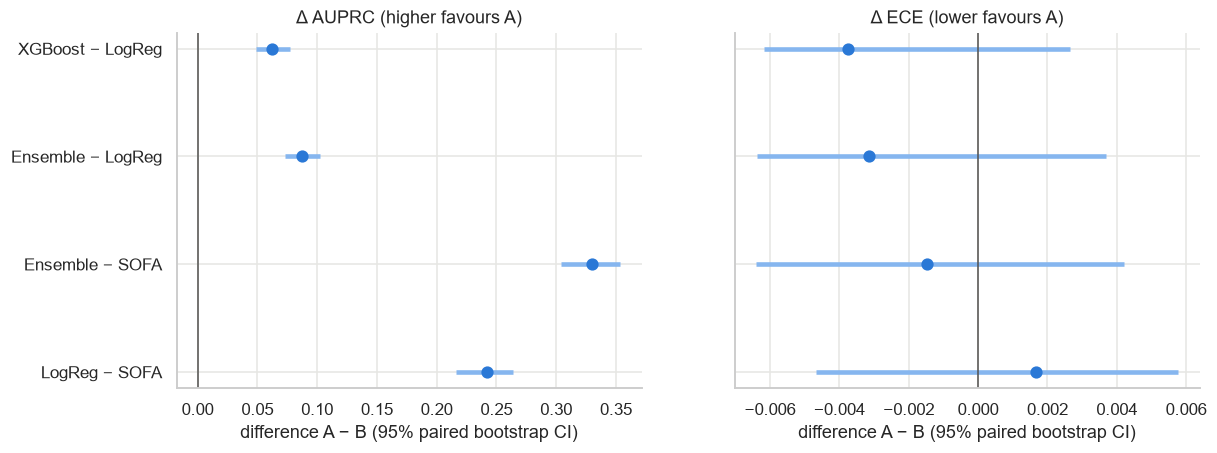

In [34]:
sub = paired[paired["metric"].isin(["AUPRC", "ECE"])].reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 0.55 * len(sub) / 2 + 2), sharey=True)
for ax, metric in zip(axes, ["AUPRC", "ECE"]):
    s = sub[sub["metric"] == metric].reset_index(drop=True)
    yy = np.arange(len(s))[::-1]
    ax.errorbar(s["difference"], yy, xerr=errbar(s["difference"] - s["ci_low"], s["ci_high"] - s["difference"]), fmt="o",
                color="#2a78d6", ecolor="#86b6ef", elinewidth=3, markersize=7)
    ax.axvline(0, color="#52514e", lw=1)
    ax.set_yticks(yy, s["comparison"]); ax.set_title(f"Δ {metric} ({'higher' if metric == 'AUPRC' else 'lower'} favours A)")
    ax.set_xlabel("difference A − B (95% paired bootstrap CI)")
savefig("05b_paired_bootstrap")

## 8. Comparison of models and approaches

One table brings together cross-validation, validation and test results and the training cost of each approach.

In [35]:
comparison = (test_results[["model", "AUROC", "AUROC_lo", "AUROC_hi", "AUPRC", "AUPRC_lo", "AUPRC_hi",
                             "Brier", "ECE", "Cal_slope", "Sensitivity", "Specificity"]]
              .merge(val_rank[["model", "val_AUPRC", "val_Brier"]], on="model", how="left")
              .merge(tuning_summary[["model", "cv_AUPRC", "cv_AUROC"]], on="model", how="left"))
comparison["type"] = comparison["model"].map(lambda m: "published score" if m in BASELINES else
                                              ("ensemble" if m == "Ensemble" else "ML model"))
comparison["calibration"] = comparison["model"].map({**cal_choice, "Ensemble": "members' own"})
comparison["train_seconds"] = comparison["model"].map(train_seconds)
comparison["final"] = comparison["model"] == FINAL_NAME
comparison = comparison.sort_values("AUPRC", ascending=False).reset_index(drop=True)
comparison.to_csv(RES_DIR / "model_comparison_full.csv", index=False)
comparison

,model,AUROC,AUROC_lo,AUROC_hi,AUPRC,AUPRC_lo,AUPRC_hi,Brier,ECE,Cal_slope,Sensitivity,Specificity,val_AUPRC,val_Brier,cv_AUPRC,cv_AUROC,type,calibration,train_seconds,final
0,Ensemble,0.8925,0.8842,0.9002,0.5588,0.5271,0.5852,0.0659,0.0026,1.0142,0.8216,0.8003,0.5530,0.0656,NaN,NaN,ensemble,members' own,NaN,True
1,XGBoost,0.8902,0.8821,0.8984,0.5339,0.5031,0.5600,0.0665,0.0020,0.9584,0.8596,0.7646,0.5383,0.0660,0.5602,0.8961,ML model,isotonic,11.6276,False
2,LightGBM,0.8893,0.8810,0.8972,0.5328,0.5019,0.5601,0.0665,0.0041,0.9653,0.8415,0.7829,0.5335,0.0663,0.5579,0.8953,ML model,isotonic,12.5341,False
3,RandomForest,0.8820,0.8722,0.8911,0.5211,0.4897,0.5479,0.0676,0.0046,0.9755,0.8007,0.7972,0.5220,0.0675,0.5392,0.8846,ML model,isotonic,5.6510,False
4,MLP,0.8878,0.8790,0.8959,0.5195,0.4896,0.5457,0.0670,0.0039,0.9786,0.8433,0.7759,0.5293,0.0668,0.5432,0.8896,ML model,isotonic,10.1735,False
5,LogReg,0.8685,0.8589,0.8781,0.4714,0.4432,0.4977,0.0709,0.0057,0.9571,0.8062,0.7861,0.4728,0.0709,0.5048,0.8790,ML model,isotonic,0.2149,False
6,SOFA,0.7022,0.6872,0.7169,0.2291,0.2094,0.2495,0.0879,0.0040,0.9739,0.8252,0.4723,NaN,NaN,NaN,NaN,published score,isotonic,0.0471,False


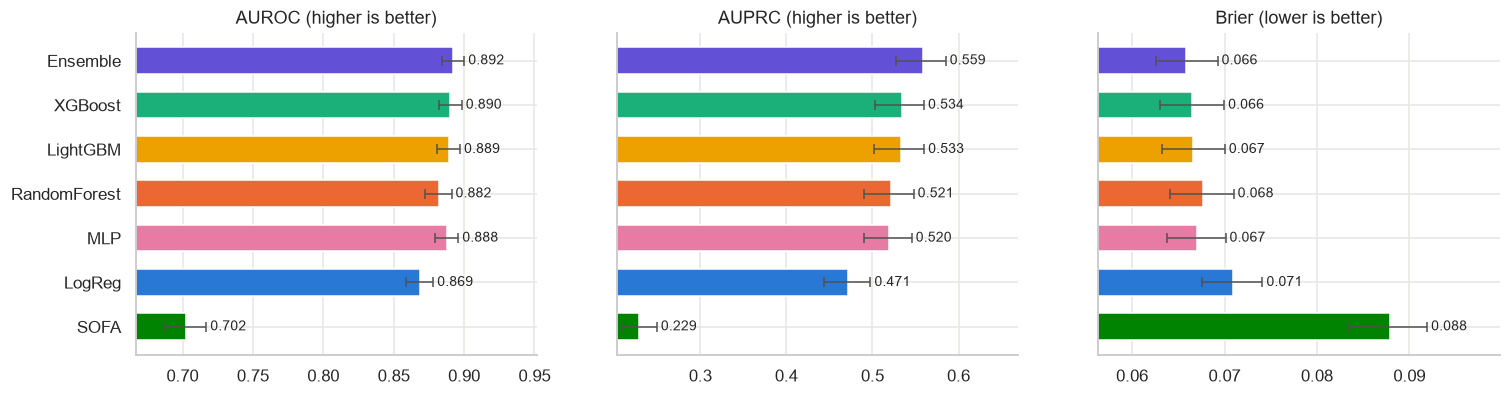

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
order = comparison["model"].tolist()
for ax, metric, better in zip(axes, ["AUROC", "AUPRC", "Brier"], ["higher", "higher", "lower"]):
    r = test_results.set_index("model").loc[order]
    ax.barh(order, r[metric], color=[PALETTE[m] for m in order], height=0.6,
            xerr=errbar(r[metric] - r[f"{metric}_lo"], r[f"{metric}_hi"] - r[metric]),
            error_kw={"ecolor": "#52514e", "elinewidth": 1, "capsize": 3})
    lo = (r[f"{metric}_lo"].min()) * (0.97 if metric != "Brier" else 0.9)
    span = r[f"{metric}_hi"].max() - lo
    ax.set_xlim(lo, r[f"{metric}_hi"].max() + 0.22 * span)
    for i, m in enumerate(order):
        ax.text(r.loc[m, f"{metric}_hi"], i, f" {r.loc[m, metric]:.3f}", va="center", fontsize=9)
    ax.set_title(f"{metric} ({better} is better)")
    if metric == "AUPRC":
        ax.axvline(y_te.mean(), color="#52514e", ls=":", lw=1)
axes[0].invert_yaxis()
savefig("05_model_comparison")

## 9. Results visualisation and performance analysis

### 9.1 ROC and precision–recall curves

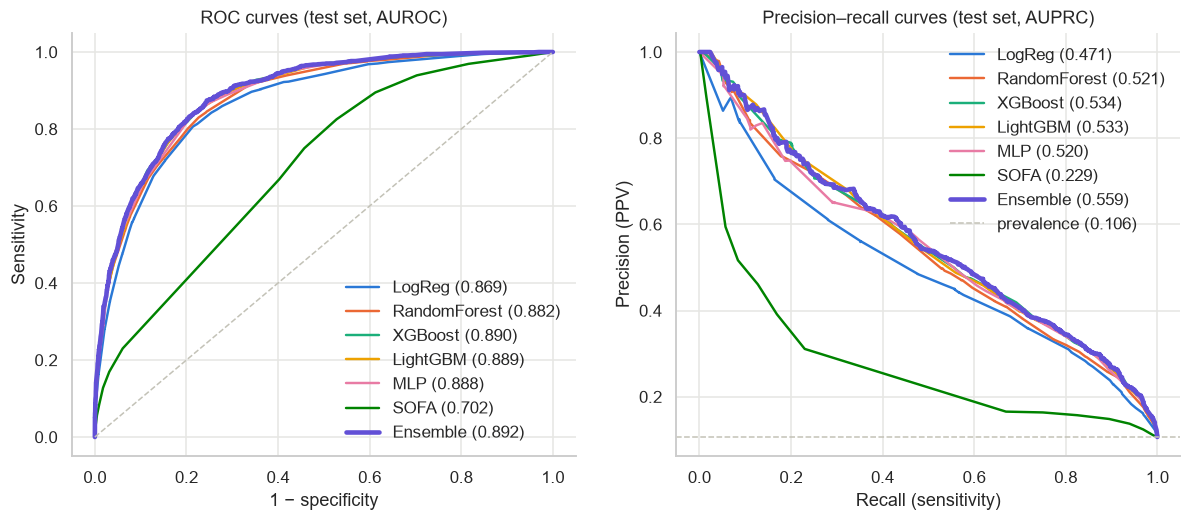

In [37]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
for m in CANDIDATES:
    fpr, tpr, _ = roc_curve(y_te, p_test[m]); pr, rc, _ = precision_recall_curve(y_te, p_test[m])
    lw = 3 if m == FINAL_NAME else 1.6
    a1.plot(fpr, tpr, color=PALETTE[m], lw=lw, label=f"{m} ({roc_auc_score(y_te, p_test[m]):.3f})")
    a2.plot(rc, pr, color=PALETTE[m], lw=lw, label=f"{m} ({average_precision_score(y_te, p_test[m]):.3f})")
a1.plot([0, 1], [0, 1], color="#c3c2b7", ls="--", lw=1)
a2.axhline(y_te.mean(), color="#c3c2b7", ls="--", lw=1, label=f"prevalence ({y_te.mean():.3f})")
a1.set(xlabel="1 − specificity", ylabel="Sensitivity", title="ROC curves (test set, AUROC)")
a2.set(xlabel="Recall (sensitivity)", ylabel="Precision (PPV)", title="Precision–recall curves (test set, AUPRC)")
a1.legend(frameon=False, loc="lower right"); a2.legend(frameon=False, loc="upper right")
savefig("06_roc_pr_curves")

### 9.2 Calibration curves on the test set

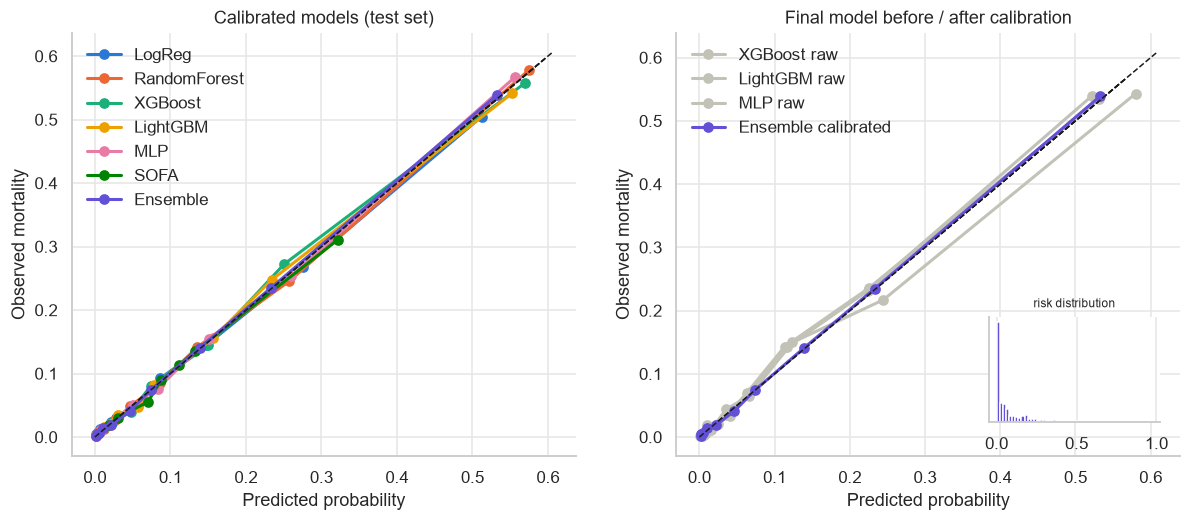

In [38]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
for m in CANDIDATES:
    plot_calibration(a1, y_te, p_test[m], label=m); a1.lines[-2].set_color(PALETTE[m])
a1.set_title("Calibrated models (test set)"); a1.legend(frameon=False)
for m in FINAL_MEMBERS:
    plot_calibration(a2, y_te, p_test_raw[m], label=f"{m} raw"); a2.lines[-2].set_color("#c3c2b7")
plot_calibration(a2, y_te, p_test[FINAL_NAME], label=f"{FINAL_NAME} calibrated"); a2.lines[-2].set_color(PALETTE[FINAL_NAME])
a2.set_title(f"Final model before / after calibration"); a2.legend(frameon=False)
ax_in = a2.inset_axes([0.62, 0.08, 0.34, 0.25])
ax_in.hist(p_test[FINAL_NAME], bins=50, color=PALETTE[FINAL_NAME]); ax_in.set_yticks([]); ax_in.set_title("risk distribution", fontsize=8)
savefig("07_calibration_test")

### 9.3 Decision-curve analysis
Net benefit weighs true alarms against false alarms at each threshold probability. A model is clinically useful where
its curve lies above both "treat all" and "treat none".

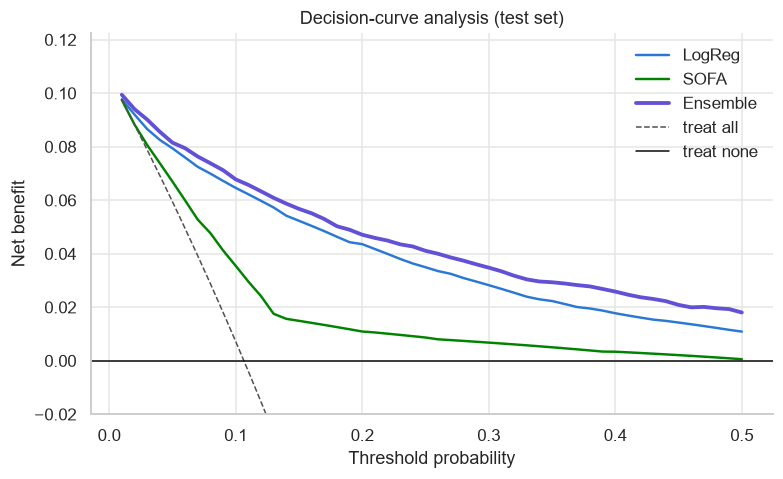

In [39]:
fig, ax = plt.subplots(figsize=(8, 4.5))
dca_all = []
for m in [x for x in CANDIDATES if x in {FINAL_NAME, "LogReg", *BASELINES}]:
    d = decision_curve(y_te, p_test[m]); d["model"] = m; dca_all.append(d)
    ax.plot(d["threshold"], d["net_benefit_model"], color=PALETTE[m], lw=2.5 if m == FINAL_NAME else 1.6, label=m)
ax.plot(d["threshold"], d["net_benefit_all"], color="#52514e", ls="--", lw=1, label="treat all")
ax.axhline(0, color="#0b0b0b", lw=1, label="treat none")
ax.set_ylim(-0.02, y_te.mean() * 1.15); ax.set(xlabel="Threshold probability", ylabel="Net benefit",
                                              title="Decision-curve analysis (test set)")
ax.legend(frameon=False)
pd.concat(dca_all).to_csv(RES_DIR / "test_decision_curve.csv", index=False)
savefig("08_decision_curve")

### 9.4 Confusion matrices of the final model

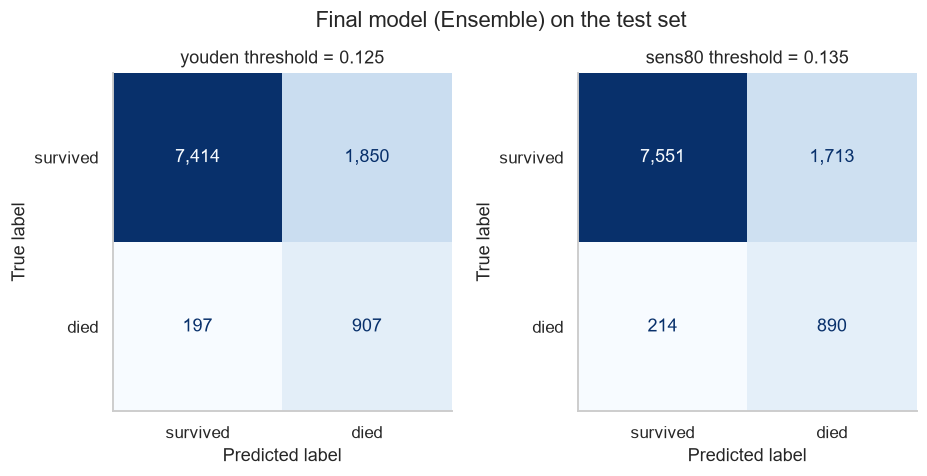

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (k, t) in zip(axes, THRESHOLDS.items()):
    cm = confusion_matrix(y_te, (p_test[FINAL_NAME] >= t).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["survived", "died"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",")
    ax.set_title(f"{k} threshold = {t:.3f}"); ax.grid(False)
fig.suptitle(f"Final model ({FINAL_NAME}) on the test set", y=1.02)
savefig("09_confusion_matrices")

### 9.5 Explainability: SHAP values
SHAP (SHapley Additive exPlanations) splits each prediction into feature contributions. For tree models the exact
TreeSHAP values are computed by the model library itself (`pred_contribs` / `pred_contrib`), so no extra package is
needed. We explain the best tree-based model; for logistic regression the standardised coefficients play this role.

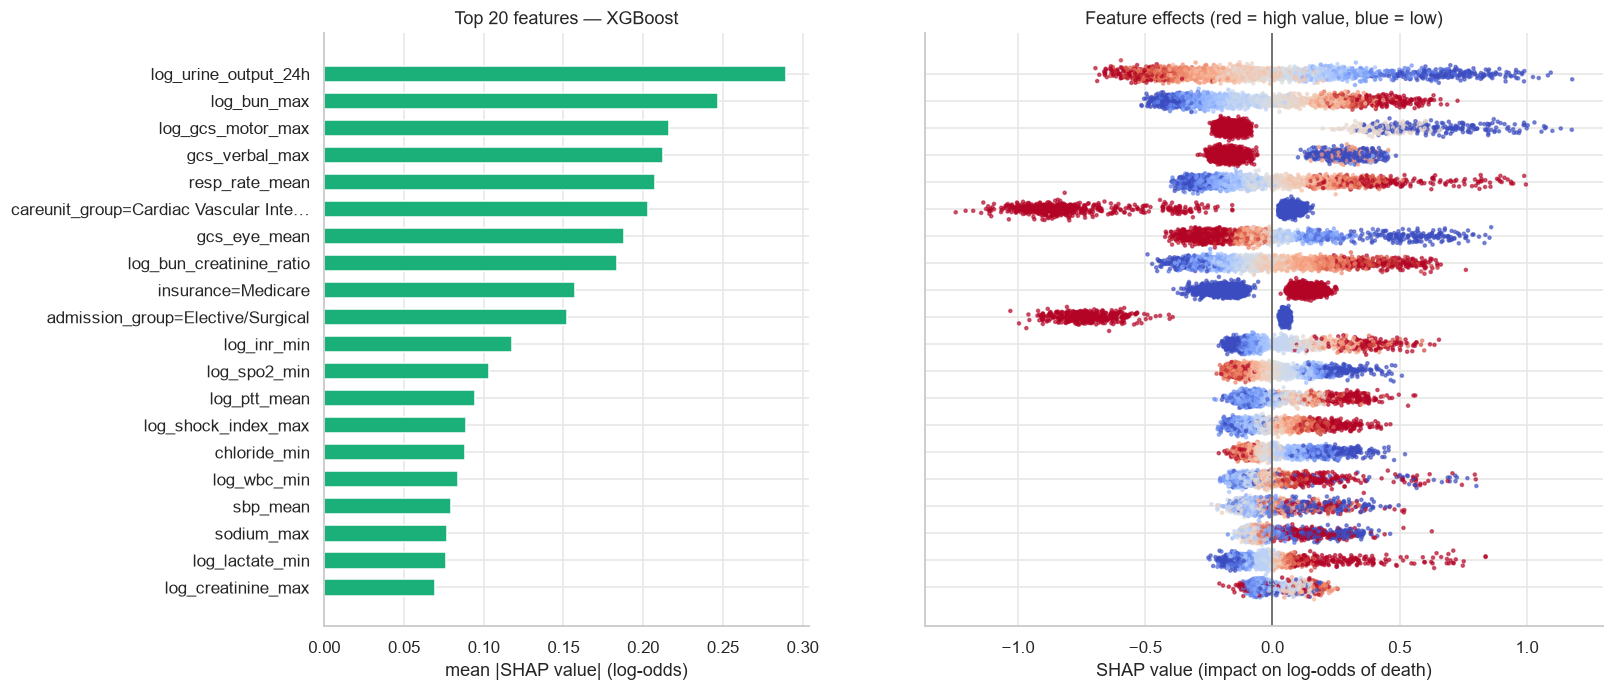

In [41]:
tree_models = [m for m in FINAL_MEMBERS if m in ("XGBoost", "LightGBM")] or \
              [m for m in val_rank["model"] if m in ("XGBoost", "LightGBM")][:1]
SHAP_MODEL = tree_models[0]
X_explain = X_te.sample(min(3000, len(X_te)), random_state=SEED)
if SHAP_MODEL == "XGBoost":
    booster = models["XGBoost"].get_booster()
    booster.set_param({"device": "cpu"})
    contrib = booster.predict(xgb.DMatrix(X_explain), pred_contribs=True)[:, :-1]
else:
    contrib = models["LightGBM"].booster_.predict(X_explain, pred_contrib=True)[:, :-1]
shap_df = pd.DataFrame(contrib, columns=FEATS_SEL)
importance = shap_df.abs().mean().sort_values(ascending=False)
importance.rename("mean_abs_shap").to_csv(RES_DIR / f"shap_importance_{SHAP_MODEL}.csv")

top = importance.index[:20][::-1]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 7), sharey=True, gridspec_kw={"width_ratios": [1, 1.4]})
a1.barh(range(len(top)), importance[top], color=PALETTE[SHAP_MODEL], height=0.6)
a1.set_yticks(range(len(top)), [f if len(f) <= 38 else f[:36] + "…" for f in top])
a1.set(xlabel="mean |SHAP value| (log-odds)", title=f"Top 20 features — {SHAP_MODEL}")
rng = np.random.default_rng(SEED)
for i, f in enumerate(top):
    v = X_explain[f].to_numpy(); s = shap_df[f].to_numpy()
    col = (v - np.nanpercentile(v, 5)) / (np.nanpercentile(v, 95) - np.nanpercentile(v, 5) + 1e-9)
    a2.scatter(s, i + rng.normal(0, 0.12, len(s)), c=np.clip(col, 0, 1), cmap="coolwarm", s=4, alpha=0.6)
a2.tick_params(axis="y", left=False); a2.axvline(0, color="#52514e", lw=1)
a2.set(xlabel="SHAP value (impact on log-odds of death)", title="Feature effects (red = high value, blue = low)")
savefig("10_shap_summary")

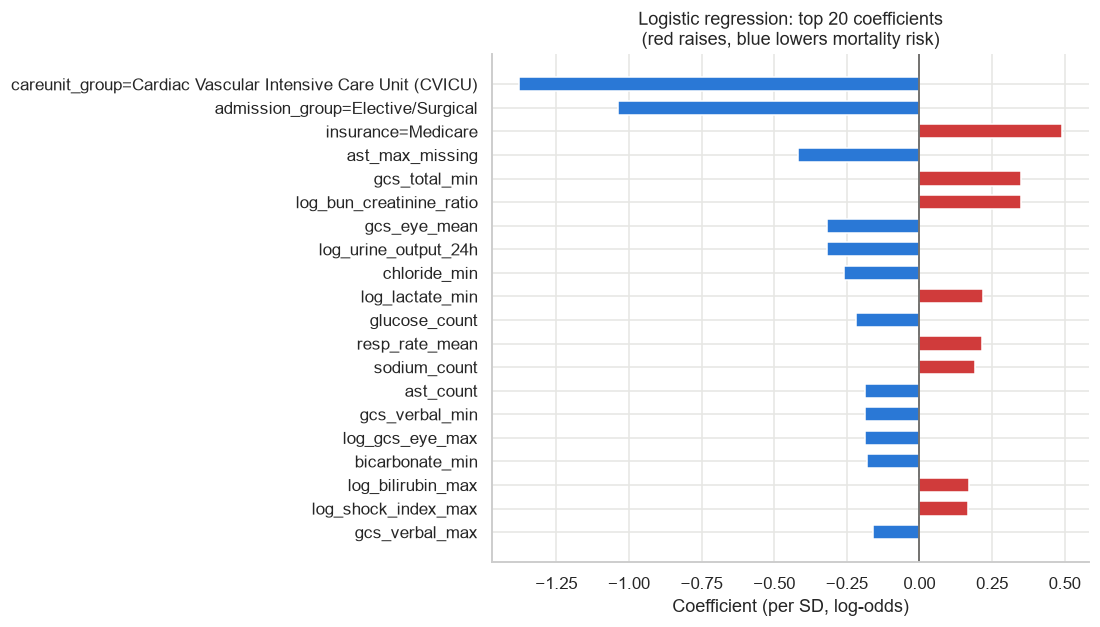

In [42]:
coef = pd.Series(models["LogReg"].coef_[0], index=FEATS_SEL).sort_values(key=np.abs, ascending=False)
coef.rename("coefficient").to_csv(RES_DIR / "logreg_coefficients.csv")
top = coef.head(20)[::-1]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#d03b3b", "#2a78d6"), height=0.6)
ax.axvline(0, color="#52514e", lw=1)
ax.set(xlabel="Coefficient (per SD, log-odds)", title="Logistic regression: top 20 coefficients\n(red raises, blue lowers mortality risk)")
savefig("11_logreg_coefficients")

### 9.6 Risk stratification
Patients are grouped into deciles of predicted risk; the observed mortality in each decile shows how well the final
model separates low- from high-risk patients (and is another view of calibration).

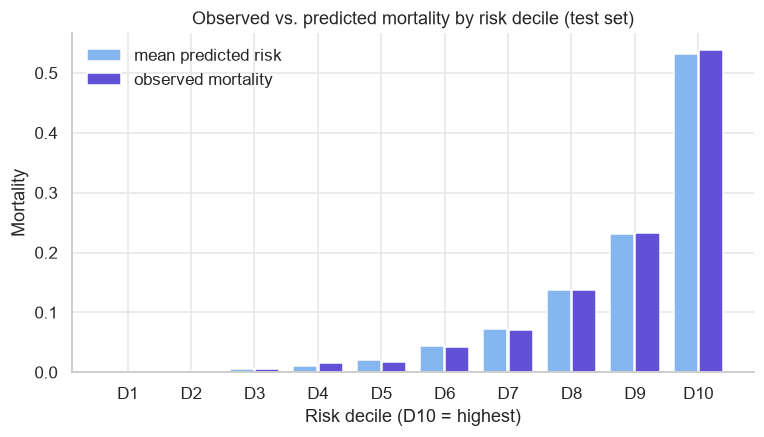

,decile,n,deaths,observed,predicted
0,1,1037,2,0.0019,0.0012
1,2,1037,3,0.0029,0.0025
2,3,1037,6,0.0058,0.0048
3,4,1036,16,0.0154,0.0103
4,5,1037,17,0.0164,0.0210
5,6,1037,43,0.0415,0.0440
6,7,1036,74,0.0714,0.0726
7,8,1037,143,0.1379,0.1374
8,9,1037,241,0.2324,0.2308
9,10,1037,559,0.5391,0.5323


In [43]:
dec = pd.DataFrame({"p": p_test[FINAL_NAME], "y": y_te})
dec["decile"] = pd.qcut(dec["p"].rank(method="first"), 10, labels=range(1, 11))
dec_tab = dec.groupby("decile", observed=True).agg(n=("y", "size"), deaths=("y", "sum"),
                                                   observed=("y", "mean"), predicted=("p", "mean")).reset_index()
dec_tab.to_csv(RES_DIR / "test_risk_deciles.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(10)
ax.bar(x - 0.2, dec_tab["predicted"], 0.38, color="#86b6ef", label="mean predicted risk")
ax.bar(x + 0.2, dec_tab["observed"], 0.38, color=PALETTE[FINAL_NAME], label="observed mortality")
ax.set_xticks(x, [f"D{i}" for i in range(1, 11)]); ax.set(xlabel="Risk decile (D10 = highest)", ylabel="Mortality",
                                                         title="Observed vs. predicted mortality by risk decile (test set)")
ax.legend(frameon=False)
savefig("12_risk_deciles")
dec_tab

## 10. Subgroup (fairness) analysis

A model that performs well on average can still be poorly calibrated or less accurate for specific groups. Following
the aims of our review (RQ6), we report AUROC, calibration and threshold metrics of the final model **by sex, age
band, race, insurance, admission type, ICU care unit and admission period (`anchor_year_group`)** on the test set.
Subgroups with fewer than 100 deaths are flagged as statistically unstable. Demographic columns come from the
unscaled Part 1 table joined in Section 2.4; they are used only for grouping, not as extra predictors.

In [44]:
available = [c for c in SUBGROUP_COLS if HAS_RAW and c in raw_te.columns]
sub_tables = []
for col in available:
    grp = raw_te[col].to_numpy()
    grp = pd.Series(grp).astype(str).where(pd.Series(grp).notna()).to_numpy()
    t = subgroup_table(y_te, p_test[FINAL_NAME], grp, THRESHOLD, n_boot=N_BOOT_SUB, seed=SEED)
    t.insert(0, "attribute", col); sub_tables.append(t)
subgroups = pd.concat(sub_tables, ignore_index=True) if sub_tables else pd.DataFrame()
subgroups.to_csv(RES_DIR / "test_subgroup_metrics.csv", index=False)
subgroups[["attribute", "group", "n", "deaths", "mortality", "mean_pred", "AUROC", "AUROC_lo", "AUROC_hi",
           "ECE", "Cal_intercept", "Sensitivity", "Specificity", "unstable"]] if len(subgroups) else "no subgroups"

,attribute,group,n,deaths,mortality,mean_pred,AUROC,AUROC_lo,AUROC_hi,ECE,Cal_intercept,Sensitivity,Specificity,unstable
0,gender,M,5888,601,0.1021,0.1018,0.8954,0.8819,0.9091,0.0063,0.0051,0.8170,0.8139,False
1,gender,F,4480,503,0.1123,0.1109,0.8882,0.8764,0.9019,0.0053,0.0189,0.8270,0.7822,False
2,age_band,66-75,2466,269,0.1091,0.1010,0.9031,0.8845,0.9211,0.0182,0.1200,0.8290,0.8079,False
3,age_band,56-65,2219,213,0.0960,0.0960,0.9090,0.8928,0.9257,0.0096,0.0005,0.8122,0.8340,False
4,age_band,76-85,2005,274,0.1367,0.1280,0.8455,0.8242,0.8687,0.0154,0.1024,0.7993,0.7291,False
5,age_band,41-55,1640,122,0.0744,0.0913,0.9217,0.8898,0.9431,0.0203,-0.3356,0.8689,0.8505,False
6,age_band,18-40,1041,60,0.0576,0.0719,0.9184,0.8770,0.9581,0.0189,-0.3625,0.8000,0.8858,True
7,age_band,>85,997,166,0.1665,0.1531,0.8325,0.7967,0.8624,0.0181,0.1291,0.8313,0.6546,False
8,race_group,White,6862,644,0.0939,0.0980,0.8853,0.8731,0.8988,0.0056,-0.0666,0.7904,0.8040,False
9,race_group,Unknown,1550,287,0.1852,0.1488,0.8984,0.8812,0.9155,0.0407,0.4090,0.8955,0.7648,False


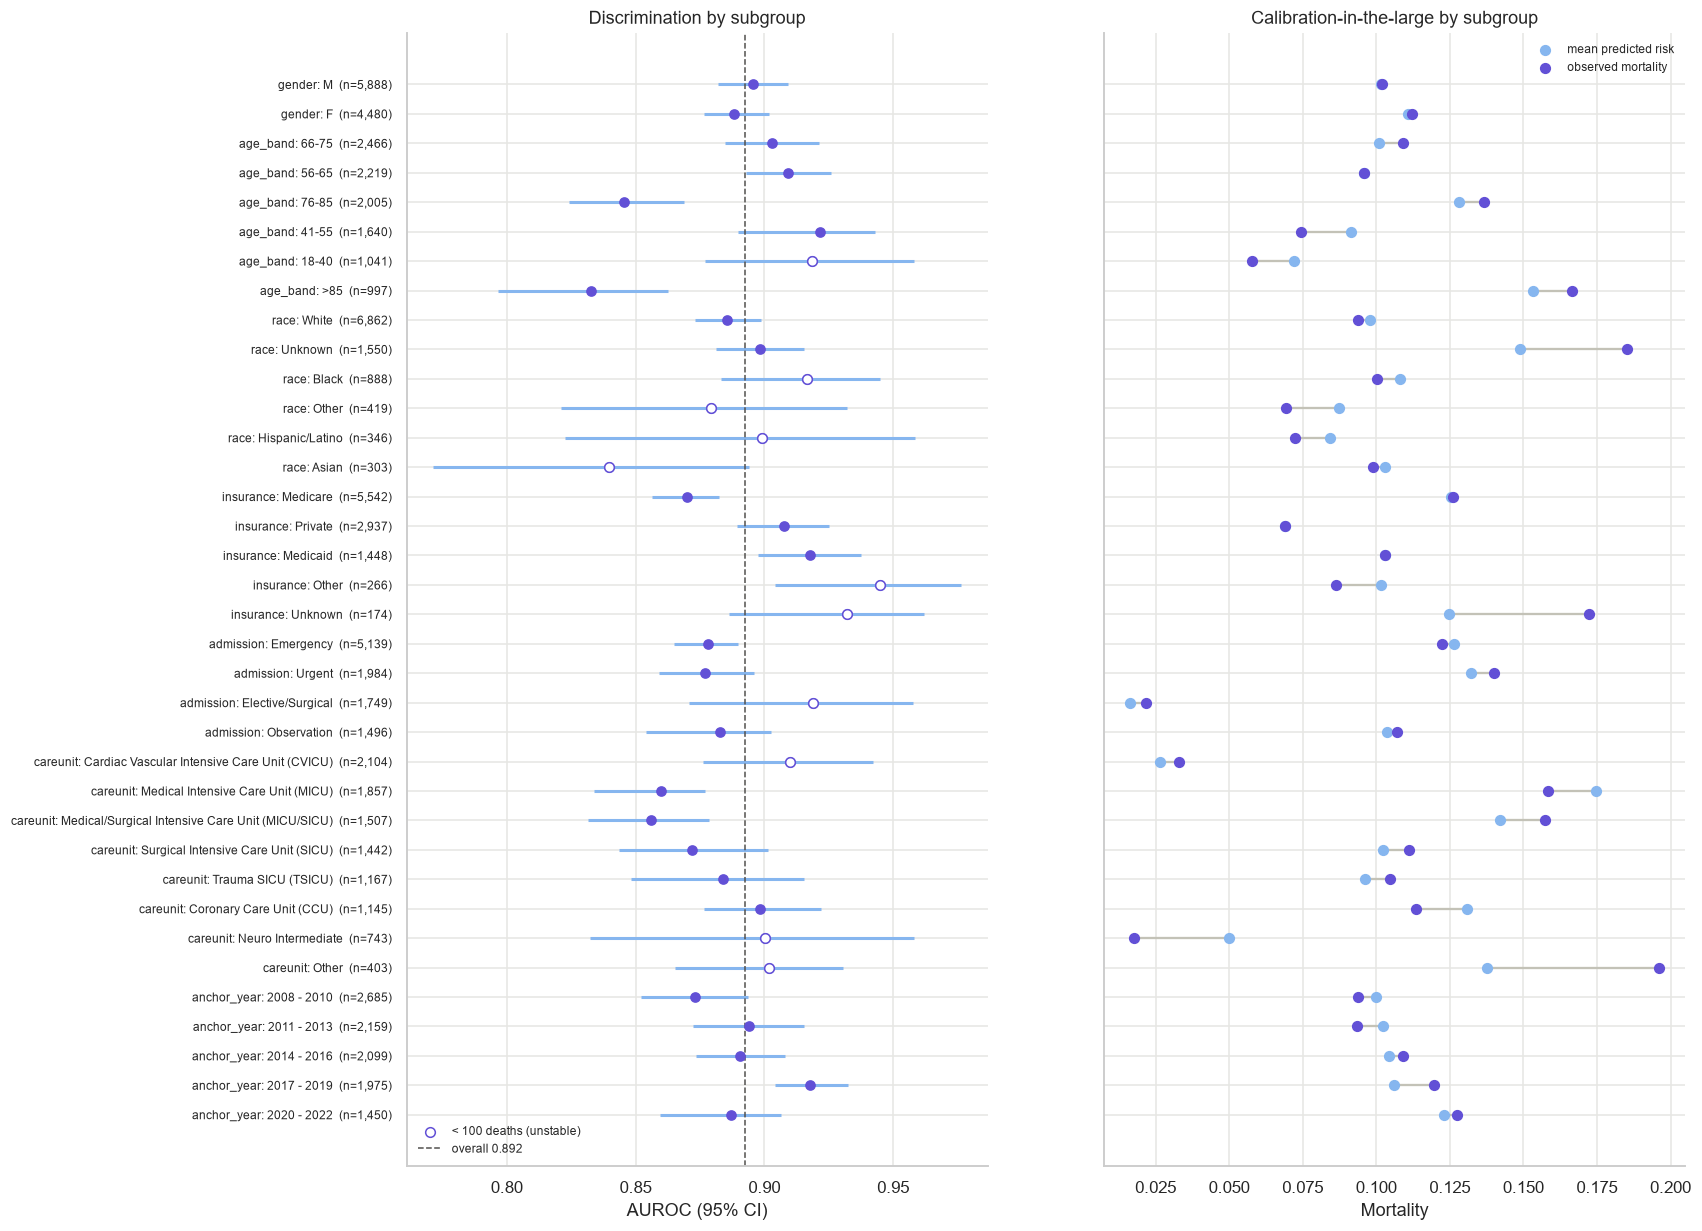

In [45]:
if len(subgroups):
    s = subgroups.reset_index(drop=True)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 0.33 * len(s) + 1.5), sharey=True)
    ypos = np.arange(len(s))[::-1]
    overall = roc_auc_score(y_te, p_test[FINAL_NAME])
    a1.errorbar(s["AUROC"], ypos, xerr=errbar(s["AUROC"] - s["AUROC_lo"], s["AUROC_hi"] - s["AUROC"]), fmt="o",
                color=PALETTE[FINAL_NAME], ecolor="#86b6ef", elinewidth=2, capsize=0, markersize=6)
    a1.scatter(s.loc[s["unstable"], "AUROC"], ypos[s["unstable"].to_numpy()], facecolor="white",
               edgecolor=PALETTE[FINAL_NAME], s=40, zorder=3, label="< 100 deaths (unstable)")
    a1.axvline(overall, color="#52514e", ls="--", lw=1, label=f"overall {overall:.3f}")
    a1.set_yticks(ypos, [f"{a.replace('_group', '')}: {g}  (n={n:,})" for a, g, n in zip(s["attribute"], s["group"], s["n"])], fontsize=8)
    a1.set(xlabel="AUROC (95% CI)", title="Discrimination by subgroup"); a1.legend(frameon=False, fontsize=8, loc="lower left")
    a2.scatter(s["mean_pred"], ypos, color="#86b6ef", s=40, label="mean predicted risk", zorder=3)
    a2.scatter(s["mortality"], ypos, color=PALETTE[FINAL_NAME], s=40, label="observed mortality", zorder=3)
    for yy, a, b in zip(ypos, s["mean_pred"], s["mortality"]):
        a2.plot([a, b], [yy, yy], color="#c3c2b7", lw=1.5)
    a2.set(xlabel="Mortality", title="Calibration-in-the-large by subgroup"); a2.legend(frameon=False, fontsize=8)
    savefig("13_subgroup_forest")

In [46]:
gap = pd.DataFrame()
if len(subgroups):
    stable = subgroups[~subgroups["unstable"]]
    gap = (stable.groupby("attribute")
           .agg(groups=("group", "size"), AUROC_min=("AUROC", "min"), AUROC_max=("AUROC", "max"),
                ECE_max=("ECE", "max"), worst_cal_intercept=("Cal_intercept", lambda v: v.loc[v.abs().idxmax()]))
           .assign(AUROC_gap=lambda d: d["AUROC_max"] - d["AUROC_min"]).sort_values("AUROC_gap", ascending=False))
    gap.to_csv(RES_DIR / "test_subgroup_gaps.csv")
    display(gap)

,groups,AUROC_min,AUROC_max,ECE_max,worst_cal_intercept,AUROC_gap
attribute,,,,,,
age_band,5,0.8325,0.9217,0.0203,-0.3356,0.0892
insurance,3,0.8701,0.9179,0.0119,0.0062,0.0478
anchor_year_group,5,0.8729,0.9176,0.0171,0.2003,0.0447
careunit_group,5,0.8560,0.8985,0.0202,-0.2280,0.0425
race_group,2,0.8853,0.8984,0.0407,0.4090,0.0131
gender,2,0.8882,0.8954,0.0063,0.0189,0.0073
admission_group,3,0.8770,0.8829,0.0162,0.0965,0.0059


## 11. Protocol experiments: missing data and temporal validation

These two experiments are pre-specified in Section 6 of our review protocol. They do **not** influence the final
model; they show, on our own cohort, how two design choices that the review audits in published studies change the
reported performance. Both use the protocol's core pair — **L2 logistic regression and XGBoost** — with the tuned
hyperparameters from Section 4 and isotonic calibration fitted on the validation set.

### 11.1 Missing-data strategies (RQ2)
Part 1 showed that bilirubin, AST, PaO₂ and PaCO₂ are missing in more than half of the stays and that missingness is
itself linked to mortality. We compare:

| Strategy | Training rows | Inputs |
|---|---|---|
| **Imputation + indicator** (Part 1 default) | all | median-imputed values + missing-value indicator columns |
| **Median imputation only** | all | median-imputed values, indicators removed |
| **Complete-case** | only stays with no missing value in the selected variables | values without indicators |
| **Native (XGBoost only)** | all | missing values left as `NaN`; XGBoost learns a default branch direction |

Every model is scored on (a) **all test stays** — what happens in deployment, where incomplete patients still need a
prediction (imputed inputs for the complete-case model) — and (b) the **complete-case test subset**, where all
strategies see the same fully observed patients.

In [47]:
missing_results = pd.DataFrame()
if HAS_RAW and MISS_BASE:
    INDICATORS = [f for f in FEATS_SEL if f.endswith("_missing")]
    FEATS_NOIND = [f for f in FEATS_SEL if f not in INDICATORS]
    cc_tr, cc_va, cc_te = (r[MISS_BASE].notna().all(axis=1).to_numpy() for r in (raw_tr, raw_va, raw_te))

    def with_nan(df, raw_part):
        # put NaN back where the raw value was missing (undo the median imputation)
        X = df[FEATS_NOIND].copy()
        for f in FEATS_NOIND:
            b = base_column(f)
            if b in MISS_BASE:
                X.loc[~raw_part[b].notna().to_numpy(), f] = np.nan
        return X

    strategies = {
        "Imputation + indicator": dict(feats=FEATS_SEL, rows=None, native=False),
        "Median imputation only": dict(feats=FEATS_NOIND, rows=None, native=False),
        "Complete-case": dict(feats=FEATS_NOIND, rows=cc_tr, native=False),
        "Native NaN (XGBoost)": dict(feats=FEATS_NOIND, rows=None, native=True),
    }
    print(f"Selected features with a raw counterpart: {len(MISS_BASE)} variables; {len(INDICATORS)} indicator columns")
    print(f"Complete cases: train {cc_tr.mean():.1%} | validation {cc_va.mean():.1%} | test {cc_te.mean():.1%} of stays")

    rows, miss_pred = [], {}
    for strat, cfg in strategies.items():
        for name in ["LogReg", "XGBoost"]:
            if cfg["native"] and name != "XGBoost":
                continue
            if cfg["native"]:
                Xa, Xv, Xt = with_nan(train, raw_tr), with_nan(val, raw_va), with_nan(test, raw_te)
            else:
                Xa, Xv, Xt = train[cfg["feats"]], val[cfg["feats"]], test[cfg["feats"]]
            keep = np.ones(len(Xa), bool) if cfg["rows"] is None else cfg["rows"]
            m = make_model(name, best_params[name]).fit(Xa[keep], y_tr[keep])
            cal = CALIBRATORS[CAL_METHOD]().fit(m.predict_proba(Xv)[:, 1], y_va)
            p = cal.predict(m.predict_proba(Xt)[:, 1])
            miss_pred[(strat, name)] = p
            for subset, mask in [("all test stays", np.ones(len(y_te), bool)), ("complete-case test subset", cc_te)]:
                ci = bootstrap_ci(y_te[mask], p[mask], 0.5, n_boot=N_BOOT_SUB, seed=SEED)
                rows.append({"strategy": strat, "model": name, "evaluated_on": subset, "train_rows": int(keep.sum()),
                             "train_rows_%": 100 * keep.mean(), "n_test": int(mask.sum()),
                             **{k: ci.loc[k, "estimate"] for k in ["AUROC", "AUPRC", "Brier", "ECE"]},
                             **{f"{k}_lo": ci.loc[k, "ci_low"] for k in ["AUPRC", "ECE"]},
                             **{f"{k}_hi": ci.loc[k, "ci_high"] for k in ["AUPRC", "ECE"]}})
    missing_results = pd.DataFrame(rows)
    missing_results.to_csv(RES_DIR / "protocol_missing_data_strategies.csv", index=False)
    display(missing_results[["strategy", "model", "evaluated_on", "train_rows_%", "AUROC", "AUPRC", "Brier", "ECE"]])
else:
    print("Raw table not available - missing-data experiment skipped")

Selected features with a raw counterpart: 32 variables; 1 indicator columns
Complete cases: train 14.6% | validation 14.7% | test 14.7% of stays


,strategy,model,evaluated_on,train_rows_%,AUROC,AUPRC,Brier,ECE
0,Imputation + indicator,LogReg,all test stays,100.0000,0.8685,0.4714,0.0709,0.0057
1,Imputation + indicator,LogReg,complete-case test subset,100.0000,0.8059,0.5971,0.1530,0.0286
2,Imputation + indicator,XGBoost,all test stays,100.0000,0.8902,0.5339,0.0665,0.0020
3,Imputation + indicator,XGBoost,complete-case test subset,100.0000,0.8363,0.6599,0.1402,0.0161
4,Median imputation only,LogReg,all test stays,100.0000,0.8688,0.4745,0.0706,0.0071
5,Median imputation only,LogReg,complete-case test subset,100.0000,0.8072,0.6028,0.1523,0.0373
6,Median imputation only,XGBoost,all test stays,100.0000,0.8896,0.5379,0.0663,0.0035
7,Median imputation only,XGBoost,complete-case test subset,100.0000,0.8355,0.6646,0.1402,0.0157
8,Complete-case,LogReg,all test stays,14.5557,0.8367,0.4372,0.0743,0.0081
9,Complete-case,LogReg,complete-case test subset,14.5557,0.8068,0.6151,0.1564,0.0720


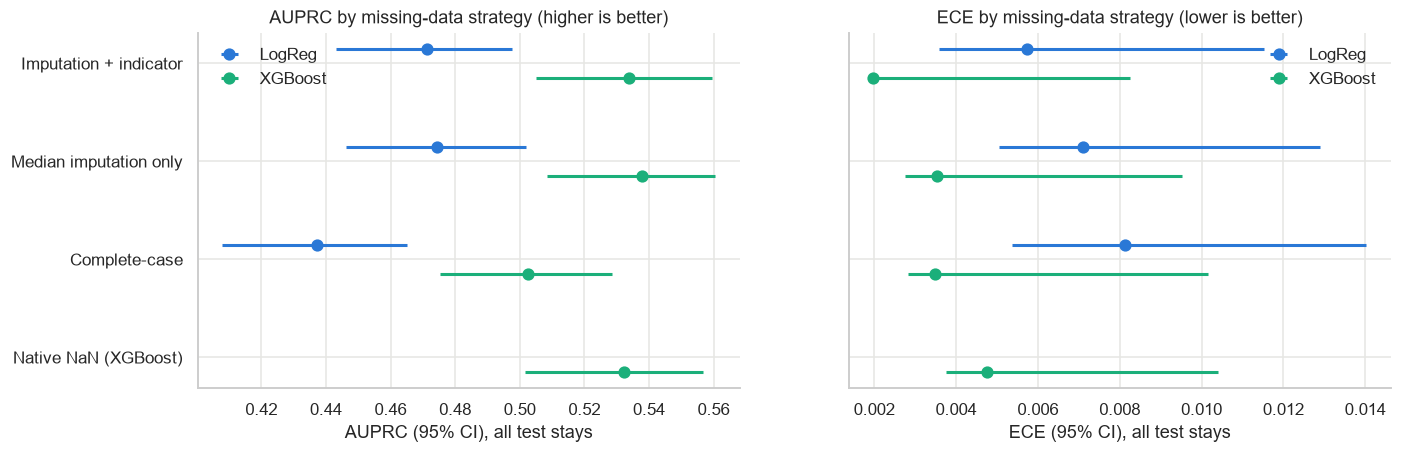

In [48]:
if len(missing_results):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
    strat_order = list(dict.fromkeys(missing_results["strategy"]))
    for ax, metric in zip(axes, ["AUPRC", "ECE"]):
        d = missing_results[missing_results["evaluated_on"] == "all test stays"]
        for j, name in enumerate(["LogReg", "XGBoost"]):
            s = d[d["model"] == name].set_index("strategy").reindex(strat_order)
            yy = np.arange(len(strat_order)) + (j - 0.5) * 0.3
            ax.errorbar(s[metric], yy, xerr=errbar(s[metric] - s[f"{metric}_lo"], s[f"{metric}_hi"] - s[metric]), fmt="o",
                        color=PALETTE[name], elinewidth=2, markersize=7, label=name)
        ax.set_yticks(range(len(strat_order)), strat_order)
        if ax is axes[0]:
            ax.invert_yaxis()          # shared y-axis: invert once
        ax.set(xlabel=f"{metric} (95% CI), all test stays",
               title=f"{metric} by missing-data strategy ({'higher' if metric == 'AUPRC' else 'lower'} is better)")
        ax.legend(frameon=False)
    savefig("14_missing_data_strategies")

**How to read it.** If removing the indicators lowers AUPRC, the *fact that a test was ordered* carries prognostic
information (informative missingness, as found in Part 1). Complete-case training discards most stays and selects a
non-representative group (patients with every test measured), so its performance on *all* test stays shows the cost of
the most common shortcut in the literature (hypothesis H2).

### 11.2 Temporal hold-out with `anchor_year_group` (RQ3)
MIMIC-IV shifts every patient's dates by a random offset; only the coarse `anchor_year_group` (3-year windows) says
roughly *when* a patient was treated, and only per patient. As the protocol notes, this supports only a limited
time-aware check: models are trained on the training stays from the **earlier periods**, calibrated on the
earlier-period validation stays, and then scored on test stays from the **earlier periods** (same era) and from the
**latest period** (future era). A drop from the first to the second suggests temporal drift that a random split
would hide.

In [49]:
temporal = pd.DataFrame()
if HAS_RAW and "anchor_year_group" in raw_tr.columns:
    periods = sorted(pd.Series(raw_tr["anchor_year_group"]).dropna().unique())
    if len(periods) >= 2:
        LATEST = periods[-1]
        early_tr = (raw_tr["anchor_year_group"] != LATEST).to_numpy() & raw_tr["anchor_year_group"].notna().to_numpy()
        early_va = (raw_va["anchor_year_group"] != LATEST).to_numpy() & raw_va["anchor_year_group"].notna().to_numpy()
        te_early = (raw_te["anchor_year_group"] != LATEST).to_numpy() & raw_te["anchor_year_group"].notna().to_numpy()
        te_late = (raw_te["anchor_year_group"] == LATEST).to_numpy()
        print(f"Periods: {periods}; held-out future period: {LATEST}")
        print(f"train (early) {early_tr.sum():,} | test early {te_early.sum():,} | test latest {te_late.sum():,} stays")
        rows = []
        for name in ["LogReg", "XGBoost"]:
            m = make_model(name, best_params[name]).fit(X_tr[early_tr], y_tr[early_tr])
            cal = CALIBRATORS[CAL_METHOD]().fit(m.predict_proba(X_va[early_va])[:, 1], y_va[early_va])
            p = cal.predict(m.predict_proba(X_te)[:, 1])
            for label, mask in [("same era (earlier periods)", te_early), (f"future era ({LATEST})", te_late)]:
                if y_te[mask].min() == y_te[mask].max():
                    continue
                ci = bootstrap_ci(y_te[mask], p[mask], 0.5, n_boot=N_BOOT_SUB, seed=SEED)
                s, i = calibration_slope_intercept(y_te[mask], p[mask])
                rows.append({"model": name, "test_period": label, "n": int(mask.sum()), "deaths": int(y_te[mask].sum()),
                             "observed_mortality": y_te[mask].mean(), "mean_predicted": p[mask].mean(),
                             "AUROC": ci.loc["AUROC", "formatted"], "AUPRC": ci.loc["AUPRC", "formatted"],
                             "ECE": ci.loc["ECE", "formatted"], "cal_slope": s, "cal_intercept": i})
        temporal = pd.DataFrame(rows)
        temporal.to_csv(RES_DIR / "protocol_temporal_holdout.csv", index=False)
        display(temporal)
if not len(temporal):
    print("anchor_year_group not available - temporal hold-out skipped")

Periods: ['2008 - 2010', '2011 - 2013', '2014 - 2016', '2017 - 2019', '2020 - 2022']; held-out future period: 2020 - 2022
train (early) 28,630 | test early 8,918 | test latest 1,450 stays


,model,test_period,n,deaths,observed_mortality,mean_predicted,AUROC,AUPRC,ECE,cal_slope,cal_intercept
0,LogReg,same era (earlier periods),8918,919,0.1031,0.1044,0.871 (0.859–0.881),0.475 (0.445–0.507),0.005 (0.004–0.012),0.9729,-0.0201
1,LogReg,future era (2020 - 2022),1450,185,0.1276,0.1268,0.851 (0.816–0.881),0.483 (0.400–0.558),0.016 (0.011–0.036),0.8118,0.0100
2,XGBoost,same era (earlier periods),8918,919,0.1031,0.1039,0.890 (0.878–0.901),0.536 (0.500–0.566),0.004 (0.004–0.011),0.9819,-0.0129
3,XGBoost,future era (2020 - 2022),1450,185,0.1276,0.1248,0.879 (0.849–0.902),0.543 (0.471–0.612),0.012 (0.009–0.031),0.8772,0.0383


**Caveat.** `anchor_year_group` is assigned per patient and the windows overlap with the shifted dates, so this is a
weak temporal test; a true temporal or external validation (e.g. on eICU) is left for future work, as stated in the
protocol.

## 12. Final model and complete machine-learning pipeline

### 12.1 End-to-end pipeline
The complete pipeline from raw MIMIC-IV tables to a risk estimate is:

```
MIMIC-IV tables ──► Part 1: cohort selection → first-24 h feature extraction → cleaning → feature engineering
                 ──► Part 1: preprocessing fitted on train (log, winsorise, impute + indicators, one-hot, scale)
                 ──► Part 1: feature selection (40 features)
                 ──► Part 2: tuned model(s) → validation-fitted calibrator → (ensemble average) → risk p
                 ──► Part 2: threshold (Youden, from validation) → high-risk alert
```

The class below packages the Part 2 stages (features → model(s) → calibration → threshold) into one object with
`predict_proba` / `predict`, saves it with `joblib`, reloads it, and checks that the reloaded pipeline reproduces the
test predictions exactly. Its input is a table already processed by Part 1 (the Part 1 preprocessing parameters are
recorded in `feature_metadata.json`).

In [50]:
class ICUMortalityPipeline:
    # features -> model(s) -> calibrator(s) -> averaged risk -> threshold
    def __init__(self, name, members, calibrators, features, thresholds, threshold_rule="youden", metadata=None):
        self.name, self.members, self.calibrators = name, members, calibrators
        self.features, self.thresholds, self.threshold_rule = features, thresholds, threshold_rule
        self.metadata = metadata or {}

    @property
    def threshold(self):
        return self.thresholds[self.threshold_rule]

    def predict_proba(self, df):
        X = df[self.features]
        ps = [self.calibrators[m].predict(self.members[m].predict_proba(X)[:, 1]) for m in self.members]
        return np.mean(ps, axis=0)

    def predict(self, df, rule=None):
        t = self.thresholds[rule or self.threshold_rule]
        return (self.predict_proba(df) >= t).astype(int)


final_pipeline = ICUMortalityPipeline(
    name=FINAL_NAME,
    members={m: models[m] for m in FINAL_MEMBERS},
    calibrators={m: calibrators[m] for m in FINAL_MEMBERS},
    features=FEATS_SEL, thresholds=THRESHOLDS,
    metadata={"trained_on": "train split (64% of cohort)", "calibrated_on": "validation split (16%)",
              "best_params": {m: best_params[m] for m in FINAL_MEMBERS},
              "calibration": {m: cal_choice[m] for m in FINAL_MEMBERS},
              "test_AUROC": float(roc_auc_score(y_te, p_test[FINAL_NAME])),
              "test_AUPRC": float(average_precision_score(y_te, p_test[FINAL_NAME])),
              "versions": {"sklearn": sklearn.__version__, "xgboost": xgb.__version__, "lightgbm": lgb.__version__}})

for m in final_pipeline.members.values():          # make the saved XGBoost model CPU-portable
    if isinstance(m, xgb.XGBClassifier):
        m.set_params(device="cpu")

model_path = MODEL_DIR / "final_model.joblib"
joblib.dump(final_pipeline, model_path)
reloaded = joblib.load(model_path)
p_check = reloaded.predict_proba(test)
assert np.allclose(p_check, p_test[FINAL_NAME], atol=1e-5), "reloaded pipeline does not reproduce predictions"
print(f"Saved {model_path.name} ({model_path.stat().st_size / 1e6:.1f} MB); reloaded predictions identical: True")

Saved final_model.joblib (5.1 MB); reloaded predictions identical: True


### 12.2 Using the pipeline: `predict_risk()`
A small helper turns pipeline output into a readable risk report. The demo scores five test stays (only the predicted
risk and the outcome are shown — no identifiers or raw patient values).

In [51]:
def predict_risk(pipeline, df):
    # return predicted mortality risk, risk band and alert flag for each row of a Part-1-processed table
    p = pipeline.predict_proba(df)
    band = pd.cut(p, [0, 0.05, 0.15, 0.30, 1.0], labels=["low", "moderate", "high", "very high"], include_lowest=True)
    return pd.DataFrame({"predicted_risk_%": np.round(100 * p, 1), "risk_band": band,
                         "alert": np.where(p >= pipeline.threshold, "HIGH RISK", "-")})


demo = test.sample(5, random_state=7)
out = predict_risk(reloaded, demo).reset_index(drop=True)
out["actual_outcome"] = np.where(demo[TARGET].to_numpy() == 1, "died", "survived")
out

,predicted_risk_%,risk_band,alert,actual_outcome
0,2.8000,low,-,survived
1,6.7000,moderate,-,survived
2,1.1000,low,-,survived
3,5.2000,moderate,-,survived
4,2.3000,low,-,survived


## 13. Results summary, conclusions and limitations

### 13.1 Key results (computed)
The cell below prints the main findings directly from the results of this run, so the summary always matches the
numbers above.

In [52]:
fr = test_results.set_index("model").loc[FINAL_NAME]
lr = test_results.set_index("model").loc["LogReg"]
summary = {
    "final_model": FINAL_NAME, "members": FINAL_MEMBERS, "calibration": {m: cal_choice[m] for m in FINAL_MEMBERS},
    "split": split_summary.set_index("set")["stays"].to_dict(),
    "test": {k: fr[f"{k}_fmt"] for k in ["AUROC", "AUPRC", "Brier", "ECE", "Cal_slope", "Cal_intercept",
                                          "Sensitivity", "Specificity", "PPV"]},
    "logreg_test": {k: lr[f"{k}_fmt"] for k in ["AUROC", "AUPRC", "Brier", "ECE"]},
    "thresholds": THRESHOLDS, "prevalence_test": float(y_te.mean()),
    "tuning_gain_AUPRC": tuning_gain.set_index("model")["AUPRC_gain"].round(4).to_dict(),
    "fast_mode": FAST, "gpu": GPU, "kaggle": IN_KAGGLE,
}
print(f"Final model: {FINAL_NAME} {'(' + ', '.join(FINAL_MEMBERS) + ')' if FINAL_NAME == 'Ensemble' else ''}")
print(f"  test AUROC {fr['AUROC_fmt']} | AUPRC {fr['AUPRC_fmt']} (baseline {y_te.mean():.3f})")
print(f"  Brier {fr['Brier_fmt']} | ECE {fr['ECE_fmt']} | calibration slope {fr['Cal_slope_fmt']}")
print(f"  at the Youden threshold ({THRESHOLD:.3f}): sensitivity {fr['Sensitivity_fmt']}, specificity {fr['Specificity_fmt']}")
print(f"Logistic regression baseline: AUROC {lr['AUROC_fmt']} | AUPRC {lr['AUPRC_fmt']}")
best_gain = tuning_gain.loc[tuning_gain["AUPRC_gain"].idxmax()]
print(f"Largest tuning gain: {best_gain['model']} (+{best_gain['AUPRC_gain']:.3f} CV AUPRC)")
sig = delong[delong["significant_0.05"]]["comparison"].tolist()
print("AUROC significantly different (DeLong p<0.05):", sig if sig else "none")
if "SOFA" in BASELINES:
    so = test_results.set_index("model").loc["SOFA"]
    print(f"SOFA baseline: AUROC {so['AUROC_fmt']} | AUPRC {so['AUPRC_fmt']}")
    summary["sofa_test"] = {k: so[f"{k}_fmt"] for k in ["AUROC", "AUPRC", "Brier", "ECE"]}
print("\nPaired bootstrap (A − B, 95% CI):")
for _, r in paired[paired["metric"].isin(["AUPRC", "ECE"])].iterrows():
    print(f"  {r['comparison']:<22} {r['metric']:<6} {r['difference']:+.4f} ({r['ci_low']:+.4f} to {r['ci_high']:+.4f})"
          f"{'  *' if r['CI_excludes_0'] else ''}")
if len(gap):
    g = gap.iloc[0]
    print(f"Largest subgroup AUROC gap (stable groups): {g.name} ({g['AUROC_min']:.3f}–{g['AUROC_max']:.3f})")
if len(missing_results):
    mr = missing_results[missing_results["evaluated_on"] == "all test stays"]
    print("\nMissing-data strategies (all test stays, AUPRC):")
    for _, r in mr.iterrows():
        print(f"  {r['model']:<8} {r['strategy']:<24} AUPRC {r['AUPRC']:.3f} | ECE {r['ECE']:.3f} | trained on {r['train_rows_%']:.0f}% of rows")
if len(temporal):
    print("\nTemporal hold-out:")
    for _, r in temporal.iterrows():
        print(f"  {r['model']:<8} {r['test_period']:<28} AUROC {r['AUROC']} | AUPRC {r['AUPRC']}")
json.dump(summary, open(RES_DIR / "summary.json", "w"), indent=2, default=str)
print(f"\nFigures: {FIG_DIR}\nTables : {RES_DIR}\nModel  : {model_path}")

Final model: Ensemble (XGBoost, LightGBM, MLP)
  test AUROC 0.892 (0.884–0.900) | AUPRC 0.559 (0.527–0.585) (baseline 0.106)
  Brier 0.066 (0.063–0.069) | ECE 0.003 (0.003–0.009) | calibration slope 1.014 (0.964–1.068)
  at the Youden threshold (0.125): sensitivity 0.822 (0.801–0.843), specificity 0.800 (0.792–0.809)
Logistic regression baseline: AUROC 0.869 (0.859–0.878) | AUPRC 0.471 (0.443–0.498)
Largest tuning gain: XGBoost (+0.025 CV AUPRC)
AUROC significantly different (DeLong p<0.05): ['Ensemble vs LogReg', 'Ensemble vs RandomForest', 'Ensemble vs XGBoost', 'Ensemble vs LightGBM', 'Ensemble vs MLP', 'Ensemble vs SOFA']
SOFA baseline: AUROC 0.702 (0.687–0.717) | AUPRC 0.229 (0.209–0.250)

Paired bootstrap (A − B, 95% CI):
  XGBoost − LogReg       AUPRC  +0.0625 (+0.0487 to +0.0775)  *
  XGBoost − LogReg       ECE    -0.0038 (-0.0062 to +0.0027)
  Ensemble − LogReg      AUPRC  +0.0874 (+0.0727 to +0.1027)  *
  Ensemble − LogReg      ECE    -0.0032 (-0.0064 to +0.0037)
  Ensemble −

### 13.2 Conclusions
Read these points together with the computed summary above; the numbers come from this run.

* **Logistic regression vs. XGBoost (H3).** The paired bootstrap in 7.4 gives the size of the gain of XGBoost over
  an equally tuned logistic regression on the same cohort. A CI that includes 0 supports H3 (small gain); a clearly
  positive AUPRC difference means non-linear effects in first-day physiology add prognostic information.
* **Published score (RQ5).** Every fitted model is compared with the SOFA score; the gap shows how much a
  multivariable model adds to a published severity score, which few published MIMIC studies report.
* **Tuning** (Section 5.1) changed cross-validated AUPRC by the amounts printed above; gains are largest for models
  whose library defaults suit an imbalanced 40-feature problem least.
* **Calibration matters as much as discrimination.** Class weighting changed ranking little but moved predicted risks
  away from observed mortality (5.2); post-hoc calibration fitted on validation data is checked on the test set in 7.1
  and Fig. 7. Reporting only AUROC would hide these differences.
* **Validation design.** Patient-grouped splits, a separate validation set for every post-hoc choice, and a single
  look at the test set give an honest estimate of performance on new patients from the same hospital.
* **Missing data (RQ2).** Section 11.1 quantifies what complete-case analysis and dropping missingness indicators
  cost on this cohort, i.e. the bias the review looks for in published studies.
* **Subgroups (RQ6).** Discrimination and calibration differ between subgroups (Section 10); groups with fewer than 100
  deaths have wide intervals and need cautious interpretation.

### 13.3 Limitations
* Single-centre, retrospective data (Beth Israel Deaconess, Boston): no external validation, and only a weak
  temporal check (Section 11.2) because MIMIC-IV dates are shifted per patient.
* SOFA is computed from first-24-h worst values without vasopressor doses (Section 3.2), so it is a close but not
  exact reproduction of the published score; the protocol's 6/12-h window comparison is not done here because Part 1
  extracted 24-h features only.
* Only the first ICU stay of adults with ≥ 24 h stay; results may not transfer to short stays or re-admissions.
* Median imputation with missing-value indicators uses the fact that a test was ordered — a pattern that may change
  with clinical practice.
* The Part 1 preprocessing (transformations, imputation) is documented in `feature_metadata.json` but not packaged as
  one `scikit-learn` object; new raw data must go through the Part 1 notebook first.
* Race and insurance groups are coarse and reflect documentation practice, not biology.

### 13.4 Reproducibility
Run Part 1 (`1_eda/`) to create `data/processed/`, then run this notebook top to bottom (on Kaggle attach the
processed files as a **private** dataset and enable the GPU). All random seeds are fixed at 42. Outputs: figures in
`2_model/figures/`, tables in `2_model/results/`, the fitted pipeline in `2_model/saved_models/final_model.joblib`
(not committed to Git).